# Deep learning · Part A: from a neuron to a U-Net picker

**A seismic network records tens of thousands of earthquakes a year at the Geysers, and every one
of them needs its P and S arrival times picked on every station before it can be located. An
analyst picks a few hundred records a day. How can a computer learn to pick them as an analyst
does — and when it has learned, what has it learned?**

Every method in this course so far has fitted a model that we wrote down: a straight line for the
magnitude–frequency relation (Session 1), travel times through a layered Earth (Session 2), the
radiation pattern of a double couple (Session 3). A **neural network** is different. It is a very
flexible function with many adjustable numbers, called **parameters**, and nobody writes down what
they should be. They are learned from examples: thousands of seismograms, each with the arrival
times an analyst picked. Fitting a network is still what we have done all along — choose the
parameters that minimise a loss — but with so many parameters that two new things are needed: a
cheap way to compute the gradient, and a way to tell learning from memorising.

This notebook builds a phase picker from the ground up, one idea at a time, and trains it on real
Geysers seismograms. The picker is a simplified copy of **PhaseNet** (Zhu & Beroza 2018), the
network our group built and that much of the field now uses, with the same names and the same
design.

## The questions this notebook answers

1. What is a neural network, and what can it represent that a linear model cannot? (A.1)
2. Where does the gradient come from, and why is it cheap even with millions of parameters? (A.2)
3. How is a network trained? (A.3)
4. How does a network say "noise, P or S" at a sample, and how is that scored? (A.4)
5. What are the Geysers seismograms and their labels, and how must they be split to test a picker
   honestly? (A.5)
6. Why use convolutions for a seismogram, and how far does a network see? (A.6–A.7)
7. How does a network output a probability at every sample, and how is it trained without
   memorising? (A.8–A.9)
8. How good are its picks, what do incomplete labels teach it, and does a probability of 0.5
   mean a 50 % chance? (A.10–A.12)

[Part B](https://colab.research.google.com/github/AI4EPS/EPS207_Observational_Seismology/blob/main/docs/notebooks/05b_picking_geysers.ipynb)
runs the published PhaseNet on Geysers earthquakes and compares it with the network trained here.


In [1]:
import importlib.util
import sys
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

BASE = "https://raw.githubusercontent.com/AI4EPS/EPS207_Observational_Seismology/main/docs/notebooks"
for module in ("geysers_data.py",):
    if "google.colab" in sys.modules or importlib.util.find_spec(module[:-3]) is None:
        for attempt in range(4):
            try:
                urllib.request.urlretrieve(f"{BASE}/{module}", module)
                break
            except Exception as exc:
                if attempt == 3:
                    raise RuntimeError(f"could not fetch {module}: {exc}; re-run this cell") from None
                time.sleep(2 * (attempt + 1))
import geysers_data as gd

torch.manual_seed(207)
rng = np.random.default_rng(207)
plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

# The U-Net of A.8 trains much faster on a graphics processor (GPU). On Colab choose
# Runtime > Change runtime type > GPU; on a Mac, PyTorch uses its GPU through "mps".
DEVICE = ("cuda" if torch.cuda.is_available() else
          "mps" if torch.backends.mps.is_available() else "cpu")
print(f"torch {torch.__version__}; the U-Net will train on: {DEVICE}")


torch 2.14.1; the U-Net will train on: mps


## A.1 · A network is a function with adjustable parts

Start with a curve every seismologist knows: the **first-arrival time** of P against distance, for
a source at the surface of a crust with two layers — a slow layer, 3 km thick, over a faster
half-space. Session 2, *Location & relocation*, computed such curves. Near the source the first
arrival is the **direct wave**, which travels in the top layer, so its time grows as distance
divided by the top-layer speed $v_1$. Beyond the **crossover distance** the first arrival is the
**head wave**, which runs along the top of the faster layer at speed $v_2$; its time grows more
slowly with distance. The curve is two straight lines that meet at a kink.

We make 200 noisy observations of this curve and ask the simplest model we know, a straight line
fitted by least squares (Session 1), to describe it.


In [2]:
v1, v2, h = 3.5, 6.0, 3.0                                        # km/s, km/s, km
intercept = 2 * h * np.sqrt(1 / v1**2 - 1 / v2**2)                 # head-wave intercept time (s)
x_cross = intercept / (1 / v1 - 1 / v2)                           # crossover distance (km)


def first_arrival(x):
    """Direct wave or head wave, whichever arrives first (s)."""
    return np.minimum(x / v1, x / v2 + intercept)


x_obs = np.sort(rng.uniform(0, 40, 200))
t_obs = first_arrival(x_obs) + rng.normal(0, 0.05, x_obs.size)    # 0.05 s picking noise
G = np.c_[np.ones_like(x_obs), x_obs]
line = np.linalg.lstsq(G, t_obs, rcond=None)[0]
print(f"crossover distance {x_cross:.1f} km; head-wave intercept {intercept:.2f} s")
print(f"straight-line fit: rms misfit {np.sqrt(np.mean((G @ line - t_obs)**2)):.3f} s "
      f"against 0.05 s of noise")


crossover distance 11.7 km; head-wave intercept 1.39 s
straight-line fit: rms misfit 0.257 s against 0.05 s of noise


The line misses by several times the noise: no single slope fits both branches. We could write the
right model down — we just did — but suppose we did not know the physics. We want a model that can
bend where the data bend.

### A neuron, and a layer of them

The building block is the **neuron**. It takes an input $x$, multiplies it by a **weight** $w$,
adds a **bias** $b$, and passes the result through a fixed non-linear function called the
**activation**. The activation used almost everywhere is the **rectified linear unit**, ReLU:

$$\mathrm{relu}(z) = \max(0, z).$$

It is zero for negative $z$ and equal to $z$ for positive $z$, so a neuron's output,
$\mathrm{relu}(wx + b)$, is flat up to $x = -b/w$ and a straight line after it: **one kink**, at a
place set by the bias. A **hidden layer** is $H$ neurons side by side, all reading the same input.
The network's output adds their outputs, each with its own weight $a_j$, plus a final bias $c$:

$$\hat t(x) = c + \sum_{j=1}^{H} a_j\, \mathrm{relu}(w_j x + b_j).$$

This is a **neural network with one hidden layer**, also called a **multilayer perceptron** (MLP).
Its parameters are the $3H + 1$ numbers $w_j, b_j, a_j, c$. Because each neuron contributes one
kink, the network is a **piecewise-linear** function with up to $H$ kinks. The word "hidden" only
means that the layer's outputs are not observed; the network computes them on the way.

Our curve has one kink, so two neurons are enough. One neuron, $\mathrm{relu}(x)$, gives the slope
$1/v_1$ from the origin; a second, starting at the crossover distance, subtracts the difference in
slope. We can set the six parameters by hand from the physics:


two neurons set by hand: rms misfit 0.048 s


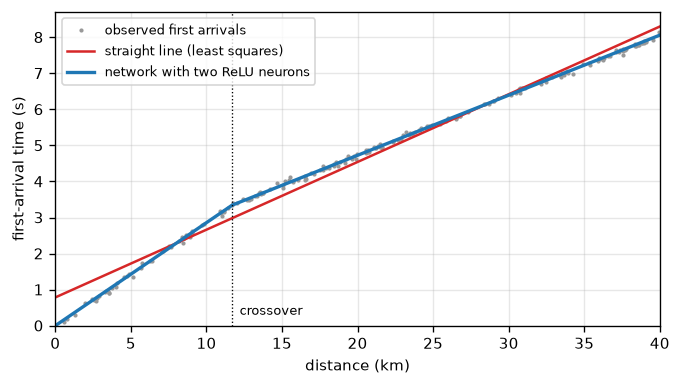

In [3]:
def mlp(x, w, b, a, c):
    """One hidden layer of ReLU neurons: c + sum_j a_j relu(w_j x + b_j)."""
    return c + np.maximum(0, np.outer(x, w) + b) @ a


w_hand = np.array([1.0, 1.0])
b_hand = np.array([0.0, -x_cross])
a_hand = np.array([1 / v1, -(1 / v1 - 1 / v2)])
c_hand = 0.0
fit_hand = mlp(x_obs, w_hand, b_hand, a_hand, c_hand)
print(f"two neurons set by hand: rms misfit {np.sqrt(np.mean((fit_hand - t_obs)**2)):.3f} s")

xx = np.linspace(0, 40, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(x_obs, t_obs, ".", c="0.6", ms=3, label="observed first arrivals")
ax.plot(xx, line[0] + line[1] * xx, c="tab:red", label="straight line (least squares)")
ax.plot(xx, mlp(xx, w_hand, b_hand, a_hand, c_hand), c="tab:blue", lw=2,
        label="network with two ReLU neurons")
ax.axvline(x_cross, c="k", lw=0.8, ls=":")
ax.text(x_cross + 0.5, 0.3, "crossover", fontsize=8)
ax.set(xlabel="distance (km)", ylabel="first-arrival time (s)", xlim=(0, 40), ylim=(0, None))
ax.legend(loc="upper left", fontsize=8)
plt.show()


Two neurons fit the curve to the noise level. Their parameters are physics: $a_1 = 1/v_1$ is the
slowness of the top layer, $a_1 + a_2 = 1/v_2$ the slowness of the half-space, and $-b_2/w_2$ the
crossover distance. Add more neurons and the network can follow more kinks; with enough of them, a
one-hidden-layer network can approximate any continuous curve on an interval as closely as we want.
That flexibility is the whole point — and it is also the danger, because a network with many
kinks can follow the noise as well as the signal.

What we cannot do for a seismogram is set the parameters by hand. PhaseNet has about 270,000 of
them, and nobody knows what any one should be. They have to be **learned**: found by minimising a
loss, exactly as least squares found the line. The loss here is still the mean squared misfit, but
the model is no longer linear in its parameters (they sit inside the ReLU), so there is no normal
equation to solve. We need the gradient of the loss with respect to every parameter, and a way to
walk downhill. A.2 computes the gradient; A.3 walks.

### Optional: why stack layers

A one-hidden-layer network can represent any continuous function, but it may need very many
neurons to do so. Feeding one layer's outputs into another layer of neurons composes kinks: a
second layer can fold the piecewise-linear output of the first, and the number of linear pieces can
grow exponentially with the number of layers while the number of parameters grows only linearly.
A deep network therefore represents complicated functions with far fewer parameters than a wide,
shallow one. This is the usual argument for depth (Prince, *Understanding Deep Learning*, ch. 4);
in practice depth also builds features in stages, which A.7 makes concrete for seismograms.


## A.2 · The gradient by the chain rule: backpropagation

Take the smallest network that shows everything: **one** neuron and a squared misfit on **one**
observation $(x, t)$. The computation runs forward in four steps, each a simple operation whose
derivative we know:

1. $z = w x + b$, whose derivatives are $\partial z/\partial w = x$ and $\partial z/\partial b = 1$;
2. $u = \mathrm{relu}(z)$, with $\partial u/\partial z = 1$ if $z > 0$ and $0$ otherwise;
3. $\hat t = a u + c$, with $\partial \hat t/\partial a = u$, $\partial \hat t/\partial u = a$ and
   $\partial \hat t/\partial c = 1$;
4. $L = (\hat t - t)^2$, with $\partial L/\partial \hat t = 2(\hat t - t)$.

### Walking the graph backwards

Such a chain of operations is a **computational graph**. We want $\partial L/\partial w$ and the
other three derivatives. The chain rule says that the derivative of $L$ with respect to anything
is the derivative of $L$ with respect to the next step, times the derivative of that step with
respect to the thing. So we start at the end, where $\partial L/\partial L = 1$, and walk
**backwards** through the graph, multiplying by one local derivative per step:

$$\frac{\partial L}{\partial \hat t} = 2(\hat t - t), \qquad
\frac{\partial L}{\partial a} = \frac{\partial L}{\partial \hat t}\,u, \qquad
\frac{\partial L}{\partial c} = \frac{\partial L}{\partial \hat t},$$

$$\frac{\partial L}{\partial u} = \frac{\partial L}{\partial \hat t}\,a, \qquad
\frac{\partial L}{\partial z} = \frac{\partial L}{\partial u}\,\mathbb{1}[z > 0], \qquad
\frac{\partial L}{\partial w} = \frac{\partial L}{\partial z}\,x, \qquad
\frac{\partial L}{\partial b} = \frac{\partial L}{\partial z}.$$

Each line reuses the one before it: the derivative arriving from later in the graph (the
**upstream gradient**) times the local derivative of one step. That is all **backpropagation** is —
the chain rule, evaluated from the loss backwards, reusing every intermediate product. We do it
with numbers, for an observation at 20 km.


In [4]:
x1, t1 = 20.0, first_arrival(20.0)
w, b, a, c = 0.8, -2.0, 0.3, 0.5

# forward: keep every intermediate value, the backward pass needs them
z = w * x1 + b
u = max(0.0, z)
t_hat = a * u + c
L = (t_hat - t1) ** 2

# backward: upstream gradient times local derivative, one step at a time
dL_dt = 2 * (t_hat - t1)
dL_da, dL_dc = dL_dt * u, dL_dt
dL_du = dL_dt * a
dL_dz = dL_du * (1.0 if z > 0 else 0.0)
dL_dw, dL_db = dL_dz * x1, dL_dz
print(f"forward:  z = {z:.2f}, u = {u:.2f}, t_hat = {t_hat:.3f} s, t = {t1:.3f} s, L = {L:.4f}")
print(f"by hand:  dL/dw = {dL_dw:.4f}, dL/db = {dL_db:.4f}, dL/da = {dL_da:.4f}, dL/dc = {dL_dc:.4f}")


forward:  z = 14.00, u = 14.00, t_hat = 4.700 s, t = 4.726 s, L = 0.0007
by hand:  dL/dw = -0.3088, dL/db = -0.0154, dL/da = -0.7205, dL/dc = -0.0515


Two checks. The first is a **finite difference**: nudge one parameter by a tiny amount and see how
much the loss changes. It needs one extra forward pass per parameter, which is why nobody trains a
network this way, but it is the honest test of a gradient. The second is **automatic
differentiation** in PyTorch, the library we use from here on. PyTorch records every operation as
it runs the forward pass — it builds the computational graph for us — and `loss.backward()` walks
it backwards exactly as we just did by hand.


In [5]:
def loss_of(w, b, a, c):
    return (a * max(0.0, w * x1 + b) + c - t1) ** 2


eps = 1e-6
fd = [(loss_of(w + eps, b, a, c) - loss_of(w - eps, b, a, c)) / (2 * eps),
      (loss_of(w, b + eps, a, c) - loss_of(w, b - eps, a, c)) / (2 * eps),
      (loss_of(w, b, a + eps, c) - loss_of(w, b, a - eps, c)) / (2 * eps),
      (loss_of(w, b, a, c + eps) - loss_of(w, b, a, c - eps)) / (2 * eps)]

params = [torch.tensor(v, dtype=torch.float64, requires_grad=True) for v in (w, b, a, c)]
tw, tb, ta, tc = params
loss = (ta * torch.relu(tw * x1 + tb) + tc - t1) ** 2
loss.backward()                                   # backpropagation, done by PyTorch
print("finite difference: " + ", ".join(f"{g:.4f}" for g in fd))
print("PyTorch autograd:  " + ", ".join(f"{p.grad.item():.4f}" for p in params))


finite difference: -0.3088, -0.0154, -0.7205, -0.0515
PyTorch autograd:  -0.3088, -0.0154, -0.7205, -0.0515


All three agree. Notice what the backward pass cost: one multiplication per step, the same work as
the forward pass. That holds for any network, however large. **The gradient with respect to every
parameter costs about as much as one more evaluation of the network.** For PhaseNet's 270,000
parameters a finite difference would need 270,000 extra forward passes; backpropagation needs one
backward pass.

This is why networks are trained by gradient descent rather than by the Gauss–Newton and
Levenberg–Marquardt methods of Session 2. Those methods need the full **Jacobian**, the derivative
of every residual with respect to every parameter: a matrix of (number of data) × (number of
parameters) entries, here millions × hundreds of thousands. Backpropagation never forms it. It
returns only the gradient of one number, the loss — which is all gradient descent needs.

### Optional: reverse mode, forward mode and the adjoint

The chain rule can be evaluated in either direction. Going forwards from one parameter gives the
derivative of every output with respect to that one parameter (**forward mode**), so a full
gradient needs one pass per parameter. Going backwards from one output gives the derivative of
that output with respect to every parameter (**reverse mode**), so a full gradient needs one pass
per output. A loss is a single number, so reverse mode wins by a factor of the number of
parameters. The price is memory: every intermediate value of the forward pass must be stored until
the backward pass uses it. Geophysicists met reverse mode long before deep learning, as the
**adjoint-state method** used in waveform and travel-time tomography: one forward simulation and one
adjoint (backward) simulation give the gradient of a misfit with respect to every cell of a
velocity model. Session 8, *Tomography*, returns to it.


## A.3 · Training: walking downhill

With the gradient in hand, **gradient descent** repeats one update: move every parameter a small
step against its gradient,

$$\theta \leftarrow \theta - \eta\, \frac{\partial L}{\partial \theta},$$

where $\theta$ stands for all the parameters together and $\eta$, the **learning rate**, sets the
step. Each pass of update is one **iteration**. The loss $L$ is now the mean squared misfit over
all 200 observations.

Unlike A.1 we give the network no help: eight neurons, with weights drawn at random. One
preparation comes first, and it matters more than it looks. Distances run from 0 to 40 km and
times from 0 to 8 s, while random starting weights are of order one. We **standardise** both:
subtract the mean and divide by the standard deviation, so input and target are each of order one
and centred on zero. Every network in this notebook is fed standardised numbers; for seismograms
(A.5) that means dividing each window by its own standard deviation.

The learning rate is the first thing to get right. We try four values on the same starting
weights.


learning rate 0.01: rms misfit after 2000 steps 0.150 s
learning rate 0.1 : rms misfit after 2000 steps 0.048 s
learning rate 1.0 : rms misfit after 2000 steps 7.131 s


learning rate 2.0 : rms misfit after 2000 steps diverged


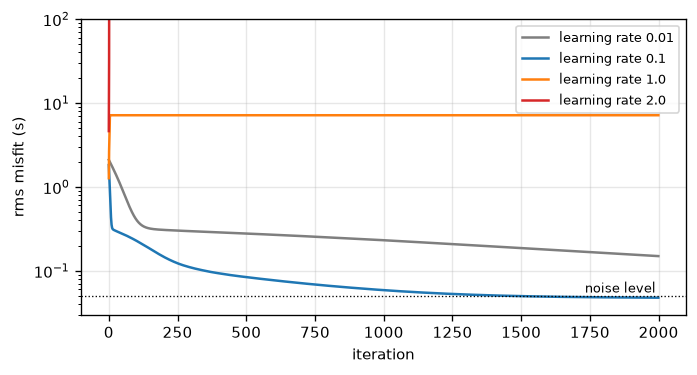

In [6]:
x_mu, x_sd, t_mu, t_sd = x_obs.mean(), x_obs.std(), t_obs.mean(), t_obs.std()
X_tt = torch.tensor((x_obs - x_mu) / x_sd, dtype=torch.float32)[:, None]
T_tt = torch.tensor((t_obs - t_mu) / t_sd, dtype=torch.float32)[:, None]


def make_mlp(hidden, seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(1, hidden), nn.ReLU(), nn.Linear(hidden, 1))


def train(net, opt, steps, batch=None, seed=0):
    """Minimise the mean squared misfit; return the rms misfit (s) on all the data after each step."""
    g = torch.Generator().manual_seed(seed)
    hist = []
    for _ in range(steps):
        idx = torch.randperm(len(X_tt), generator=g)[:batch] if batch else slice(None)
        loss = F.mse_loss(net(X_tt[idx]), T_tt[idx])
        opt.zero_grad()                  # forget the previous step's gradient
        loss.backward()                  # backpropagation fills p.grad for every parameter
        opt.step()                       # theta <- theta - eta * grad
        with torch.no_grad():
            hist.append(F.mse_loss(net(X_tt), T_tt).item())
    return np.sqrt(np.nan_to_num(hist, nan=1e12)) * t_sd           # back to seconds


fig, ax = plt.subplots(figsize=(6.5, 3.2))
for lr, col in ((0.01, "tab:gray"), (0.1, "tab:blue"), (1.0, "tab:orange"), (2.0, "tab:red")):
    net = make_mlp(8, seed=1)
    hist = train(net, torch.optim.SGD(net.parameters(), lr=lr), 2000)
    ax.semilogy(hist, c=col, label=f"learning rate {lr}")
    print(f"learning rate {lr:<4}: rms misfit after 2000 steps "
          + ("diverged" if hist[-1] > 1e6 else f"{hist[-1]:.3f} s"))
ax.axhline(0.05, c="k", ls=":", lw=0.8)
ax.text(1990, 0.055, "noise level", ha="right", fontsize=8)
ax.set(xlabel="iteration", ylabel="rms misfit (s)", ylim=(0.03, 100))
ax.legend(fontsize=8)
plt.show()


Too small a step (0.01) and the network is still far from the data after 2,000 iterations. A step
ten times larger (0.1) reaches the noise level. At 1.0 the first steps overshoot so far that every
neuron's input becomes negative for all the data: the neurons die and pass no gradient, and what is
left is a single constant, the output bias, which each step throws from one side of the data to
the other, so the misfit never falls. At 2.0 the steps grow without bound and the loss diverges. There is no formula for the right learning rate — it is found by trying, which is why the
first thing to do with any new network is to watch its loss curve.

### Mini-batches: stochastic gradient descent

Computing the gradient over all the data at every step is affordable for 200 points but not for a
million seismograms. **Stochastic gradient descent** (SGD) estimates the gradient from a small
random **mini-batch** of examples at each step. The estimate is noisy, but it is unbiased and
costs a fraction of the full one, so far more steps fit in the same time. One pass through all
the training examples is an **epoch**.

### Momentum and Adam

Two refinements are used almost everywhere. **Momentum** keeps a running average of recent
gradients and steps along it, so the noise of the mini-batches averages out and the steps grow
along directions where the gradient keeps the same sign. **Adam** (Kingma & Ba 2015) adds a second
running average, of the squared gradient, and divides each parameter's step by its square root, so
every parameter moves at a similar rate whatever the scale of its gradient. Adam's default
learning rate, $10^{-3}$, works for a wide range of networks, which is why it is the usual first
choice; PhaseNet is trained with it. We compare the three on mini-batches of 16 observations. One
run can be lucky, so each curve is the median over ten random starts.


SGD               : median rms misfit after 1500 steps 0.189 s; never below 0.06 s


SGD with momentum : median rms misfit after 1500 steps 0.053 s; below 0.06 s after 1205 steps


Adam              : median rms misfit after 1500 steps 0.054 s; below 0.06 s after 786 steps


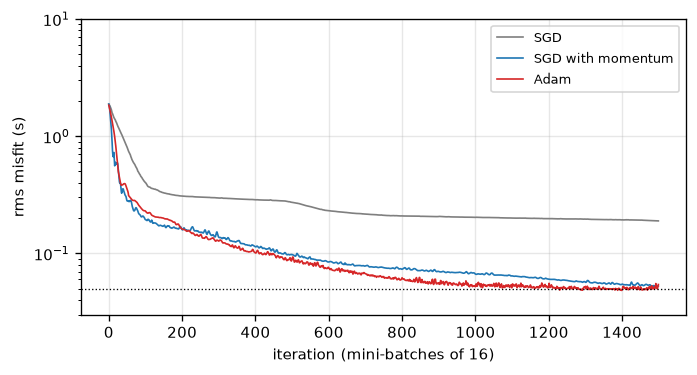

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
runs = {"SGD": lambda p: torch.optim.SGD(p, lr=0.01),
        "SGD with momentum": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
        "Adam": lambda p: torch.optim.Adam(p, lr=0.01)}
for (name, make_opt), col in zip(runs.items(), ("tab:gray", "tab:blue", "tab:red")):
    curves = []
    for seed in range(10):
        net = make_mlp(8, seed=seed)
        curves.append(train(net, make_opt(net.parameters()), 1500, batch=16, seed=seed))
    med = np.median(curves, axis=0)
    reach = np.argmax(med < 0.06) if (med < 0.06).any() else None
    ax.semilogy(med, c=col, lw=1, label=name)
    print(f"{name:<18}: median rms misfit after 1500 steps {med[-1]:.3f} s; "
          + (f"below 0.06 s after {reach} steps" if reach else "never below 0.06 s"))
ax.axhline(0.05, c="k", ls=":", lw=0.8)
ax.set(xlabel="iteration (mini-batches of 16)", ylabel="rms misfit (s)", ylim=(0.03, 10))
ax.legend(fontsize=8)
plt.show()


With the same learning rate, momentum and Adam reach the noise level in a fraction of the steps
plain SGD needs. The curves are jagged because every step sees a different mini-batch.

### Where it starts matters

The loss of a network has many valleys, as the likelihood of a Gaussian mixture had many local
optima in Session 4, *Clustering*. Training from different random starting weights can end in
different places. With ReLU neurons there is a specific way to fail: a neuron whose input
$w_j x + b_j$ is negative for every observation outputs zero everywhere, so its gradient is zero
and it never recovers — a **dead neuron**. With only two neurons, losing one leaves a straight
line. We train the two-neuron network of A.1, and an eight-neuron one, from ten random starts each.


In [8]:
for hidden in (2, 8):
    finals = []
    for seed in range(10):
        net = make_mlp(hidden, seed=seed)
        finals.append(train(net, torch.optim.Adam(net.parameters(), lr=0.01), 2000)[-1])
    finals = np.array(finals)
    print(f"{hidden} neurons, rms misfit from 10 random starts (s): "
          + ", ".join(f"{f:.2f}" for f in finals) + f"  -> {np.sum(finals < 0.06)} of 10 at the noise level")


2 neurons, rms misfit from 10 random starts (s): 0.26, 0.24, 0.26, 0.05, 2.14, 0.05, 0.26, 0.05, 0.23, 0.26  -> 3 of 10 at the noise level


8 neurons, rms misfit from 10 random starts (s): 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05  -> 10 of 10 at the noise level


Two neurons are exactly enough to represent the curve, yet most random starts fail: they end on the
straight-line misfit of A.1 (about 0.26 s), a poorer valley, or at a constant because both neurons
died. Eight neurons succeed far more often, although six of them are not needed to represent the
curve. Two things make failures rare in practice. Networks are given **more neurons than strictly
needed**, so a few dead ones or a poor start do not matter, and their starting weights are drawn at
a carefully chosen scale: **He initialisation** draws each
weight with variance $2/n_\text{in}$, where $n_\text{in}$ is the number of inputs to the neuron,
so that signals neither shrink nor grow as they pass through many layers. PyTorch's layers start
from a scale of this kind by default.


## A.4 · From numbers to classes: softmax and cross-entropy

A phase picker does not predict a number. At every sample of a seismogram it must say which of
three **classes** the sample belongs to: **noise**, **P** or **S**. Session 3, *Focal mechanisms*,
met the two-class version: a polarity is up or down, and the logistic loss scores a predicted
probability against the observed sign. Here is the version with any number of classes.

The network outputs one number per class at every sample, called a **logit**: $s_\text{noise}$,
$s_P$, $s_S$. Any real values are allowed. The **softmax** turns them into probabilities that are
positive and add up to one:

$$p_k = \frac{e^{s_k}}{e^{s_\text{noise}} + e^{s_P} + e^{s_S}}.$$

The largest logit gets the largest probability, and adding the same constant to all three logits
changes nothing. With two classes the softmax is the logistic function of Session 3.

The loss is the **cross-entropy**. If the true class at a sample is $k$, the loss there is
$-\ln p_k$: zero when the network gives the true class probability one, and growing without bound
as that probability goes to zero. It is the negative log-likelihood of the labels, so minimising it
is maximum likelihood, as least squares was for Gaussian noise in Session 1.


In [9]:
def softmax(s):
    e = np.exp(s - s.max())
    return e / e.sum()


for s in ([2.0, 0.5, -1.0], [0.0, 0.0, 0.0], [-1.0, 4.0, 0.0]):
    p = softmax(np.array(s))
    print(f"logits {s} -> probabilities noise {p[0]:.2f}, P {p[1]:.2f}, S {p[2]:.2f};"
          f"  cross-entropy if the truth is P: {-np.log(p[1]):.2f}")
print(f"ln 3 = {np.log(3):.2f}")


logits [2.0, 0.5, -1.0] -> probabilities noise 0.79, P 0.18, S 0.04;  cross-entropy if the truth is P: 1.74
logits [0.0, 0.0, 0.0] -> probabilities noise 0.33, P 0.33, S 0.33;  cross-entropy if the truth is P: 1.10
logits [-1.0, 4.0, 0.0] -> probabilities noise 0.01, P 0.98, S 0.02;  cross-entropy if the truth is P: 0.02
ln 3 = 1.10


The middle case is worth remembering. A network that knows nothing gives every class the same
probability, one third, and its cross-entropy is $\ln 3 \approx 1.10$. So **the loss of a freshly
initialised three-class network should be close to 1.10**; if it is not, something is wrong with
the data or the code before any training has happened. This is the first check in Karpathy's
widely used recipe for training networks (Karpathy 2019), and we use it in A.8.

### Soft labels

An analyst's pick is not exact: two careful analysts can differ by a few hundredths of a second.
PhaseNet therefore does not label a single sample as P. It spreads the label over a short
**Gaussian** centred on the pick: the target probability of P is $\exp[-(i - i_P)^2 / 2\sigma^2]$
at sample $i$, with $\sigma = 10$ samples (0.1 s), and the probability of noise is whatever is
left. The target is then a probability distribution $q$ rather than a single class, and the
cross-entropy becomes $-\sum_k q_k \ln p_k$. PhaseNet subtracts the part that does not depend on
the network, $-\sum_k q_k \ln q_k$, so that a perfect prediction scores exactly zero. The result is
the **Kullback–Leibler divergence** between the target and the prediction, and it is the loss we
train with:


In [10]:
def kl_divergence_loss(logits, target):
    """PhaseNet's loss: cross-entropy against soft targets minus the targets' own entropy.
    logits, target: (batch, 3 classes, samples). A perfect prediction scores 0."""
    log_t = torch.nan_to_num(torch.log(target))                     # 0 log 0 = 0
    return (F.cross_entropy(logits, target, reduction="none") + (target * log_t).sum(1)).mean()


q = torch.tensor([[[0.9, 0.2], [0.1, 0.8], [0.0, 0.0]]])            # two samples, soft targets
print(f"perfect logits: {kl_divergence_loss(torch.log(q + 1e-9), q).item():.4f};  "
      f"uninformed logits: {kl_divergence_loss(torch.zeros_like(q), q).item():.3f}")


perfect logits: 0.0000;  uninformed logits: 0.686


## A.5 · The Geysers seismograms, their labels, and an honest split

A picker learns from examples, so before any network we look hard at the examples. They come from
the Northern California Earthquake Data Center (NCEDC): for every earthquake in the catalogue, the
seismogram recorded at each station, with the P and S arrival times picked for that catalogue. We
keep the earthquakes of 2016 inside the producing field and the stations inside the 40 km study
circle — the same region as the project notebook — and only velocity sensors:

- **BG.DP**, the Geysers' own borehole geophones, operated for the field and densest near the
  steam wells;
- **NC.EH**, short-period seismometers of the regional network, almost all recording only the
  vertical component;
- **NC.HH** and **BK.HH**, broadband seismometers.

Every example is a **window** of 30 s, sampled 100 times a second (3,000 samples), on three
components: east, north and vertical (E, N, Z). A station that records only Z has zeros on E and
N. Amplitudes range over four orders of magnitude between a small distant earthquake and a large
near one, so each window is divided by its own standard deviation, the standardisation of A.3.

The file also holds the arrival times — the **labels** — as sample indices inside each window, and
a table that says, for every window, which earthquake and station it is, the distance between
them, the magnitude, and which part of the experiment the window belongs to.


In [11]:
waves = np.load(gd.asset("geysers_picking_2016.npz"))
X_all = waves["waveform"].astype(np.float32)          # (windows, 3 components E N Z, 3000 samples)
P_all, S_all = waves["p_index"], waves["s_index"]     # up to 4 arrivals per window; -1 = none
meta = pd.read_csv(gd.asset("geysers_picking_2016.csv.gz"))
with open(gd.asset("geysers_picking_2016_stats.json")) as f:
    import json
    stats = json.load(f)
FS, NT = 100, X_all.shape[-1]
print(f"{len(meta):,} windows of {NT / FS:.0f} s from {meta.event_id.nunique():,} earthquakes "
      f"at {meta.station.nunique()} stations\n")
parts = {"train": "training", "val": "validation", "test": "test", "case": "five case earthquakes"}
print(f"{'':<24}{'earthquakes':>12}{'earthquake windows':>20}{'noise-only windows':>20}")
for key, name in parts.items():
    m = meta[meta.set == key]
    print(f"{name:<24}{m.event_id.nunique():>12,}{(m.kind != 'noise').sum():>20,}{(m.kind == 'noise').sum():>20,}")


2,540 windows of 30 s from 930 earthquakes at 55 stations

                         earthquakes  earthquake windows  noise-only windows
training                         508               1,119                 163
validation                       210                 454                  70
test                             207                 452                  68
five case earthquakes              5                 214                   0


Each row is one part of the data, and A.5's last subsection explains why there are three plus the
cases. An **earthquake window** holds the arrivals of an earthquake at one station. A
**noise-only window** was cut from the same recording before the earthquake arrived, and checked
against the catalogue to contain no other earthquake; a picker must learn to stay silent on it.
The **five case earthquakes** are kept whole — every station of each — to look at closely, and
are used for nothing else. We begin with the largest of the five, the M 2.9 of 31 March
2016 — the reference event of the project notebook — drawn as a **record section**: the vertical
component of every station, placed at its distance from the epicentre.


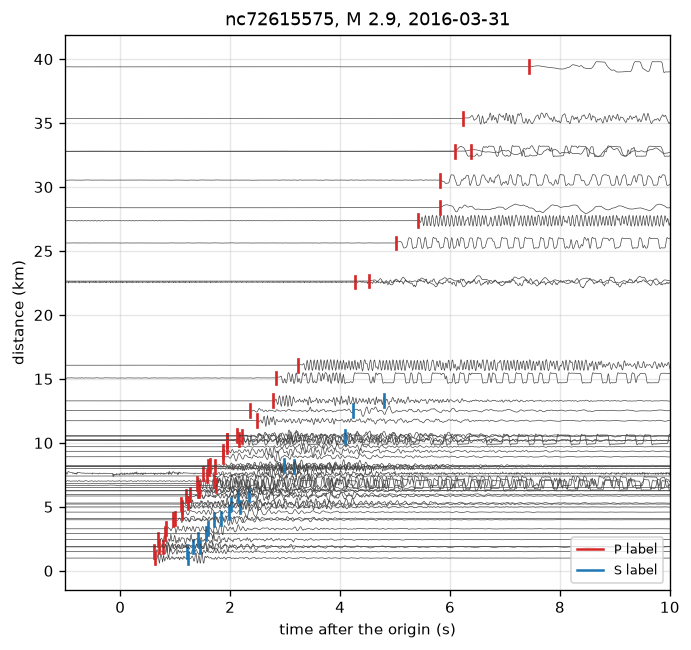

50 stations within 40 km; P labelled on 50, S labelled on 18; farthest S label at 13.3 km


In [12]:
def record_section(ax, eid, comp=2, span=(-1, 10), gain=0.45):
    """Vertical traces of one case event against distance, with the catalogue's P and S labels."""
    rows = meta.index[(meta.kind == "case") & (meta.event_id == eid)]
    t = np.arange(NT) / FS - 3.0                      # case windows start 3 s before the origin
    keep = (t >= span[0]) & (t <= span[1])
    for i in rows:
        x = X_all[i, comp] if X_all[i, comp].any() else X_all[i].max(0)
        d = meta.distance_km[i]
        ax.plot(t[keep], d + gain * x[keep] / (np.abs(x[keep]).max() + 1e-9), c="0.25", lw=0.4)
        for idx, col in ((P_all[i], "tab:red"), (S_all[i], "tab:blue")):
            for j in idx[idx >= 0]:
                ax.plot([t[j]] * 2, [d - 0.5, d + 0.5], c=col, lw=1.6)
    ax.set(xlabel="time after the origin (s)", ylabel="distance (km)", xlim=span)


ref = meta[(meta.case == "reference")].iloc[0]
fig, ax = plt.subplots(figsize=(6.5, 6))
record_section(ax, ref.event_id)
ax.plot([], [], c="tab:red", label="P label"); ax.plot([], [], c="tab:blue", label="S label")
ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"{ref.event_id}, M {ref.magnitude:.1f}, {ref.window_start[:10]}")
plt.show()
case_ref = meta[(meta.kind == "case") & (meta.event_id == ref.event_id)]
print(f"{len(case_ref)} stations within 40 km; P labelled on {(P_all[case_ref.index, 0] >= 0).sum()}, "
      f"S labelled on {case_ref.s_labelled.sum()}; farthest S label at "
      f"{case_ref[case_ref.s_labelled].distance_km.max():.1f} km")


The P arrivals (red) line up along a curve that steepens with distance — the moveout of A.1 — and
the S arrivals (blue) follow later on a steeper one. Every station has a P label. The S labels stop
well inside the circle, although the S wave is plainly visible on the farther traces. The analyst
did not pick them: S is harder to pick than P, because it arrives inside the P coda, and an S pick
far away adds little to a location that the near stations already constrain.

Look also at the far traces after the P: their oscillations have flat tops of constant height.
Those are NC.EH short-period stations, whose signals reach the data centre over analog telemetry
with a limited range; when the ground moves more than that range allows, the record **clips** —
it saturates at its maximum and stays there. The P onset survives clipping, but the shape of what
follows, including the S, is lost. We count windows whose largest component has a run of flat
samples at its maximum:


In [13]:
def clipped(x, level=0.8, flat=0.02, min_samples=40):
    """True if a trace sits flat near its own maximum for at least min_samples samples."""
    mx = np.abs(x).max()
    run = (np.abs(x) > level * mx) & (np.abs(np.diff(x, prepend=x[0])) < flat * mx)
    starts = np.flatnonzero(np.diff(np.r_[0, run.astype(int)]) == 1)
    ends = np.flatnonzero(np.diff(np.r_[run.astype(int), 0]) == -1)
    return mx > 0 and np.sum([e - s + 1 for s, e in zip(starts, ends) if e - s >= 3]) >= min_samples


eh = meta[(meta.kind != "noise") & (meta.instrument == "EH")]
eh_clip = pd.Series([clipped(X_all[i, 2]) for i in eh.index], index=eh.index)
print("NC.EH windows that clip, by magnitude: " + ", ".join(
    f"{m} {eh_clip[eh.mbin == m].mean():.0%}" for m in ["M<0.5", "M0.5-1.5", "M1.5-2.5", "M>=2.5"]))
print(f"stations of the reference event that clip: {int(eh_clip[eh.event_id == ref.event_id].sum())}, "
      f"all NC.EH")


NC.EH windows that clip, by magnitude: M<0.5 0%, M0.5-1.5 0%, M1.5-2.5 7%, M>=2.5 26%
stations of the reference event that clip: 10, all NC.EH


A quarter of the short-period records of earthquakes above M 2.5 clip, and none below M 1.5;
the BG geophones and the broadband stations record the same earthquakes without clipping.
We keep clipped windows — a picker in operation meets them — but they are one more reason the S
labels thin out where they do. This is the most important fact about these labels, and it holds
for the whole year:


In [14]:
sd = pd.DataFrame(stats["s_by_distance"])
si = pd.DataFrame(stats["s_by_instrument"]).set_index("instrument")
print("share of records with an S label, all reviewed 2016 field events:")
for r in sd.itertuples():
    print(f"  {r.distance_lo:>2}-{r.distance_hi:<2} km: {r.s_labelled:5.1%} of {r.records:>6,} records")
print("by sensor: " + ", ".join(f"{k} {v.s_labelled:.1%} (vertical only: {v.vertical_only:.0%})"
                                for k, v in si.iterrows()))


share of records with an S label, all reviewed 2016 field events:
   0-2  km: 49.8% of 10,348 records
   2-5  km: 30.9% of 38,023 records
   5-10 km: 11.2% of 43,719 records
  10-15 km:  1.6% of 21,308 records
  15-20 km:  1.0% of  5,585 records
  20-30 km:  0.5% of  6,408 records
  30-40 km:  0.1% of  4,876 records
by sensor: DP 20.9% (vertical only: 0%), EH 0.6% (vertical only: 94%), HH 26.1% (vertical only: 0%)


Half the records within 2 km carry an S label, and almost none beyond 15 km do. On the NC.EH
stations, nearly all of which record only the vertical component, almost no S is ever picked: S
shakes the ground mostly horizontally. **A missing S label does not mean there is no S.** If a
network is told that everything without a label is noise, it will be taught to call distant S
arrivals noise. A.11 measures what that costs and how to avoid it.

### Which events are reviewed

The catalogue's picks are of two kinds: **manual**, reviewed by an analyst, and **automatic**, made
by the network's own picking software and never checked. Which events get reviewed depends on
their size:


In [15]:
for r in stats["review_by_magnitude"]:
    print(f"  M {r['mag_lo']:>4} to {r['mag_hi']:<4}: {r['reviewed']:>5,} of {r['events']:>5,} events reviewed")


  M -2.0 to 0.5 : 1,385 of 3,441 events reviewed
  M  0.5 to 1.0 :   818 of 5,735 events reviewed
  M  1.0 to 1.5 : 1,358 of 2,487 events reviewed
  M  1.5 to 2.0 :   606 of   613 events reviewed
  M  2.0 to 6.0 :   207 of   214 events reviewed


Every event above M 1.5 is reviewed; most between M 0.5 and 1.0 are not. We use **reviewed events
only**, so that the labels are an analyst's, but keep reviewed small events deliberately, so the
picker sees the whole range of sizes. (Part B looks at an automatic-only event.)

### Splitting so that the test is honest

A network must be scored on examples it never trained on: a **training set** to fit the
parameters, a **validation set** to make decisions during training (when to stop, which settings
to keep), and a **test set**, touched once at the end, to report how good the picker is. Session 1
split data at random. Seismograms cannot be split at random, for three physical reasons.

1. **The records of one earthquake are not independent.** They share the source, the magnitude and
   the origin time. So we split whole earthquakes, never single records.
2. **Earthquakes repeat.** At the Geysers, half of all earthquakes have another earthquake within
   about 110 m of them (below). Two earthquakes that close give nearly identical seismograms at
   the same station, because the waves travel the same path. With a random split of earthquakes,
   the test set would be full of near-copies of training examples, and would measure how well the
   network remembers paths, not how well it picks. So we cut the field into **cells of 1 km by
   1 km** and assign whole cells: every earthquake in a cell goes to the same set.
3. **Performance depends on distance and magnitude.** Small and distant earthquakes are harder.
   A test set drawn in natural proportions would be dominated by small, near records and say
   little about the rest. So the validation and test sets are **balanced**: the same number of
   records in every combination of four magnitude ranges and three distance ranges, with the
   sensor types mixed in each. Every score can then be reported per combination, and an average
   over combinations weights each equally.


distance from each 2016 earthquake to its nearest neighbour: median 110 m, 10 % of earthquakes within 44 m


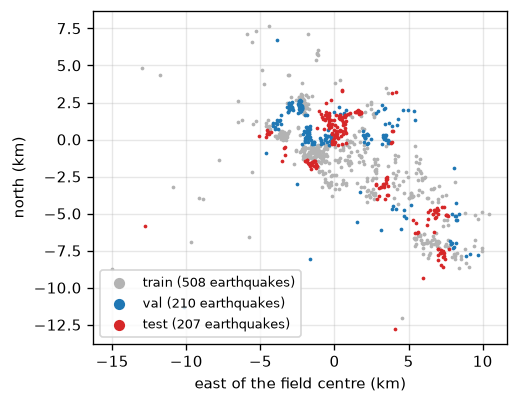


val: records per magnitude and distance
dbin      0-5 km  5-15 km  15-40 km
mbin                               
M<0.5         40       40        17
M0.5-1.5      40       40        40
M1.5-2.5      40       40        40
M>=2.5        39       40        38

test: records per magnitude and distance
dbin      0-5 km  5-15 km  15-40 km
mbin                               
M<0.5         40       40        12
M0.5-1.5      40       40        40
M1.5-2.5      40       40        40
M>=2.5        40       40        40


In [16]:
q = stats["nn_km_quantiles"]
print(f"distance from each 2016 earthquake to its nearest neighbour: median {q['50'] * 1000:.0f} m, "
      f"10 % of earthquakes within {q['10'] * 1000:.0f} m")
ev = meta[meta.kind == "event"].drop_duplicates("event_id")
fig, ax = plt.subplots(figsize=(5.2, 3.6))
colours = {"train": "0.7", "val": "tab:blue", "test": "tab:red"}
for s, col in colours.items():
    e = ev[ev.set == s]
    ax.scatter((e.event_longitude - gd.CENTER[1]) * gd.KM_LON, (e.event_latitude - gd.CENTER[0]) * gd.KM_LAT,
               s=5, c=col, label=f"{s} ({len(e)} earthquakes)", lw=0)
ax.set(aspect="equal", xlabel="east of the field centre (km)", ylabel="north (km)")
ax.legend(fontsize=8, markerscale=3, loc="lower left")
plt.show()
for s in ("val", "test"):
    x = meta[(meta.set == s) & (meta.kind == "event")]
    tab = pd.crosstab(x.mbin, x.dbin).reindex(index=["M<0.5", "M0.5-1.5", "M1.5-2.5", "M>=2.5"],
                                               columns=["0-5 km", "5-15 km", "15-40 km"])
    print(f"\n{s}: records per magnitude and distance"); print(tab)


The three sets interleave across the field, cell by cell, so each covers the whole field while no
test earthquake has a near-copy in training. The validation and test tables hold forty records in
every cell but one: earthquakes below M 0.5 are seldom recorded beyond 15 km, so that combination
has fewer — which is itself a fact about detection, not a flaw in the selection.

Finally we turn the labels into training targets, exactly as PhaseNet does (A.4): a Gaussian of
width $\sigma = 10$ samples centred on each P and each S, and noise as whatever probability is
left.


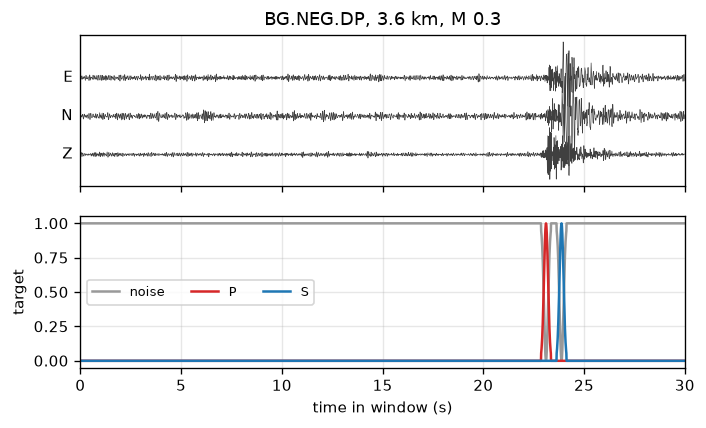

In [17]:
def generate_labels(p_idx, s_idx, nt=NT, phase_width=60):
    """PhaseNet's targets (3, nt) for noise, P, S: Gaussians of sigma = phase_width / 6 samples."""
    sigma = phase_width / 6
    t = np.arange(nt)
    y = np.zeros((3, nt), np.float32)
    for k, picks in ((1, p_idx), (2, s_idx)):
        for i in picks[picks >= 0]:
            g = np.exp(-(t - i) ** 2 / (2 * sigma ** 2))
            g[g < 0.05] = 0
            y[k] += g
    y[0] = np.clip(1 - y[1] - y[2], 0, 1)
    return y


Y_all = np.stack([generate_labels(p, s) for p, s in zip(P_all, S_all)])
i = meta.index[(meta.set == "train") & meta.s_labelled & (meta.distance_km.between(3, 6))][0]
t = np.arange(NT) / FS
fig, axs = plt.subplots(2, 1, figsize=(6.5, 3.6), sharex=True)
for k, name in enumerate("ENZ"):
    axs[0].plot(t, X_all[i, k] / 8 + 2 - k, lw=0.4, c="0.25")
    axs[0].text(-0.4, 2 - k, name, ha="right", va="center")
axs[0].set(yticks=[], title=f"{meta.network[i]}.{meta.station[i]}.{meta.instrument[i]}, "
                            f"{meta.distance_km[i]:.1f} km, M {meta.magnitude[i]:.1f}")
for k, (name, col) in enumerate((("noise", "0.6"), ("P", "tab:red"), ("S", "tab:blue"))):
    axs[1].plot(t, Y_all[i, k], c=col, label=name)
axs[1].set(xlabel="time in window (s)", ylabel="target", xlim=(0, 30))
axs[1].legend(fontsize=8, ncol=3)
plt.show()


## A.6 · Why convolution

The MLP of A.1 reads its whole input at once, with one weight for every input value. For a window
of 3 × 3,000 samples that is 9,000 weights per neuron, and — the real problem — every weight is
tied to one position in the window. A neuron that learns what a P arrival looks like at sample
1,000 knows nothing about a P arrival at sample 1,500. An arrival can be anywhere in a window, so
the network would have to learn the same pattern again at every position.

We can see this happen. The task: decide whether a 4 s piece of the vertical component (400
samples) contains a P arrival. We train on pieces where the P sits in the **first half** and test
on pieces where it sits in the **second half**, with equal numbers of pure-noise pieces in both.


In [18]:
def pieces(sets, where, n_per=1, seed=0, L=400):
    """4 s vertical pieces: P at a position in `where` (samples), or noise; labels 1 / 0."""
    g = np.random.default_rng(seed)
    xs, ys = [], []
    for i in meta.index[meta.set.isin(sets) & (meta.kind == "event")]:
        p = P_all[i, 0]
        z = X_all[i, 2] if X_all[i, 2].std() > 0 else X_all[i].max(0)
        for _ in range(n_per):
            off = g.integers(*where)
            if L <= p - off + L <= NT and p - off >= 0:
                xs.append(z[p - off:p - off + L]); ys.append(1)
            if p > L + 200:                                       # noise before the P arrival
                a = g.integers(0, p - L - 100)
                xs.append(z[a:a + L]); ys.append(0)
    x = np.array(xs, np.float32)
    x /= x.std(1, keepdims=True) + 1e-6
    return torch.tensor(x)[:, None], torch.tensor(ys, dtype=torch.float32)


xa, ya = pieces(["train"], (40, 160), n_per=2)        # P in the first half: samples 40-160
xb, yb = pieces(["val"], (240, 360), seed=1)           # P in the second half: samples 240-360
xc, yc = pieces(["val"], (40, 160), seed=2)            # first half again, for comparison
print(f"training pieces {len(ya)}, of which {int(ya.sum())} contain a P; test pieces {len(yb)}")


training pieces 4175, of which 2237 contain a P; test pieces 827


A **convolution** reads the input differently. It slides one short **kernel** — a handful of
weights, here 7 — along the trace and at every position takes the weighted sum of the samples under
it:

$$y_i = \sum_{j=0}^{K-1} w_j\, x_{i+j} + b.$$

The same $K$ weights are used at every position: **weight sharing**. Two things follow. The layer
has $K + 1$ parameters however long the trace is, instead of one per sample. And if the input
shifts, the output shifts by the same amount and is otherwise unchanged: the layer is
**translation-equivariant**. A kernel that responds to the onset of a P wave responds to it
wherever it occurs. A **convolutional layer** applies several kernels at once, each producing one
output trace called a **channel**, and reads several input channels (the three components) by
giving each kernel one set of weights per input channel. Layers stack like the MLP's: convolution,
then ReLU, then the next convolution.

To turn a trace of feature channels into one yes/no answer, the convolutional network takes the
**maximum** of each channel over the whole piece — "did this feature occur anywhere?" — and feeds
those maxima to a final linear layer. We train both networks the same way: the MLP, and a small
convolutional network (CNN).


MLP: 25,729 parameters; accuracy on training pieces 98%, new pieces with P in the first half 81%, P in the second half 65%
CNN:  3,761 parameters; accuracy on training pieces 95%, new pieces with P in the first half 93%, P in the second half 93%


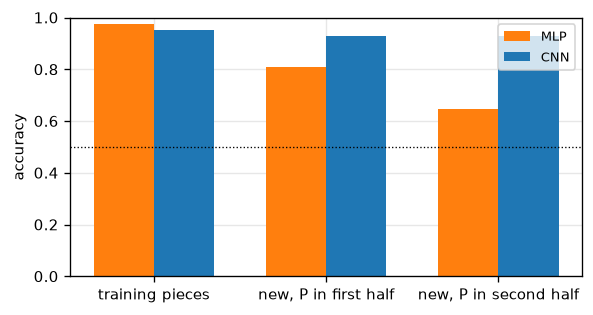

In [19]:
def mlp_detector():
    return nn.Sequential(nn.Flatten(), nn.Linear(400, 64), nn.ReLU(), nn.Linear(64, 1))


class CNNDetector(nn.Module):
    def __init__(self, ch=16):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(1, ch, 7, padding=3), nn.ReLU(),
                                  nn.Conv1d(ch, ch, 7, padding=3), nn.ReLU(),
                                  nn.Conv1d(ch, ch, 7, padding=3), nn.ReLU())
        self.out = nn.Linear(ch, 1)

    def forward(self, x):
        return self.out(self.conv(x).amax(-1))          # max over time: "did it occur anywhere?"


def fit_detector(net, epochs=30):
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    for _ in range(epochs):
        for idx in torch.randperm(len(ya)).split(64):
            loss = F.binary_cross_entropy_with_logits(net(xa[idx])[:, 0], ya[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    return net


def accuracy(net, x, y):
    with torch.no_grad():
        return ((net(x)[:, 0] > 0).float() == y).float().mean().item()


torch.manual_seed(0)
detectors = {"MLP": fit_detector(mlp_detector()), "CNN": fit_detector(CNNDetector())}
acc = {k: (accuracy(n, xa, ya), accuracy(n, xc, yc), accuracy(n, xb, yb)) for k, n in detectors.items()}
for k, n in detectors.items():
    print(f"{k}: {sum(p.numel() for p in n.parameters()):>6,} parameters; accuracy on training pieces "
          f"{acc[k][0]:.0%}, new pieces with P in the first half {acc[k][1]:.0%}, "
          f"P in the second half {acc[k][2]:.0%}")

fig, ax = plt.subplots(figsize=(5.5, 2.8))
w = 0.35
for j, (k, col) in enumerate((("MLP", "tab:orange"), ("CNN", "tab:blue"))):
    ax.bar(np.arange(3) + (j - 0.5) * w, acc[k], w, color=col, label=k)
ax.set_xticks(range(3), ["training pieces", "new, P in first half", "new, P in second half"])
ax.axhline(0.5, c="k", ls=":", lw=0.8)
ax.set(ylabel="accuracy", ylim=(0, 1))
ax.legend(fontsize=8)
plt.show()


Both networks learn the training pieces, and both do well on new pieces with the P where they saw
it in training. When the P moves to the second half, the MLP drops most of the way to guessing
(50 %): its weights for the second half never saw an arrival. The CNN, with several times fewer
parameters, does as well on the shifted pieces as on the others. That is the case for convolution in one figure: **the right structure —
here, that an arrival looks the same wherever it occurs — lets a network learn from far fewer
examples, and generalise to cases it never saw.** Building such an assumption into a network's
design is called an **inductive bias**.

### STA/LTA is a convolution

Seismologists used convolutions to detect arrivals long before neural networks. The classic
trigger, **STA/LTA** (Allen 1978), divides the average energy in a short window (the
short-term average, STA, here 0.5 s) by the average in a long window before it (the long-term
average, LTA, here 5 s), and declares an arrival where the ratio jumps. Each average is a
convolution of the squared trace with a box-shaped kernel of fixed weights. A CNN does the same
kind of computation, but **learns** its kernels from the labels instead of having them chosen by
hand — and stacks many of them.


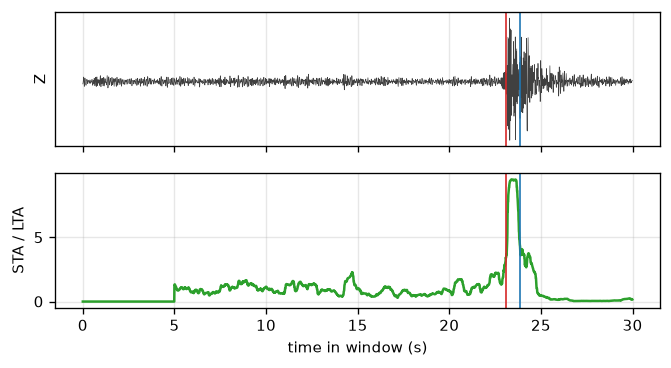

STA/LTA peaks at 23.39 s; P label at 23.11 s


In [20]:
def sta_lta(z, sta=0.5, lta=5.0):
    """Allen-style trigger ratio with box kernels, computed as two convolutions."""
    e = torch.tensor(z, dtype=torch.float32)[None, None] ** 2
    ks, kl = int(sta * FS), int(lta * FS)
    s = F.conv1d(F.pad(e, (ks - 1, 0)), torch.ones(1, 1, ks) / ks)        # past ks samples
    l = F.conv1d(F.pad(e, (kl - 1, 0)), torch.ones(1, 1, kl) / kl)
    r = (s / (l + 1e-6))[0, 0].numpy()
    r[:kl] = 0                     # the first long window is not yet full: no ratio there
    return r


z = X_all[i, 2]
r = sta_lta(z)
fig, axs = plt.subplots(2, 1, figsize=(6.5, 3.2), sharex=True)
axs[0].plot(t, z, c="0.25", lw=0.4); axs[0].set(yticks=[], ylabel="Z")
axs[1].plot(t, r, c="tab:green"); axs[1].set(xlabel="time in window (s)", ylabel="STA / LTA")
for ax in axs:
    ax.axvline(t[P_all[i, 0]], c="tab:red", lw=1); ax.axvline(t[S_all[i, 0]], c="tab:blue", lw=1)
plt.show()
print(f"STA/LTA peaks at {t[np.argmax(r)]:.2f} s; P label at {t[P_all[i, 0]]:.2f} s")


The ratio jumps at the P arrival, and again, less clearly, at the S. STA/LTA detects that
*something* arrived; it does not say whether it is P or S, and its peak is late by a fraction of
the short window. Telling the phases apart needs context — what came before — which is the next
question.

## A.7 · How far the network sees: the receptive field

An output sample of a convolutional network depends only on a limited stretch of the input around
it: its **receptive field**. One kernel of 7 samples sees 7 samples. A second layer of kernel 7 on
top sees 13: each of its 7 inputs saw 7. In general $n$ stacked layers of kernel $K$ see
$n(K-1) + 1$ samples — the field grows by only $K - 1$ per layer.

That is too slow. To call an arrival S rather than P, the network must see the P that came before
it, so its receptive field must span the **S–P time**. At the Geysers that is mostly under 1.5 s
(150 samples), but it reaches several seconds at 40 km, and to call a window noise-free the
network should see much more. The fix is **downsampling**: a convolution with **stride** $s$
moves its kernel $s$ samples at a time, so its output is $s$ times shorter, and every layer after
it sees $s$ times further in input samples. PhaseNet downsamples by 4 at each of four stages.

The receptive field can be measured rather than derived. Ask how one output sample depends on
every input sample: the gradient of that output with respect to the input, by backpropagation
(A.2). Wherever the gradient is non-zero, the input can affect the output.


In [21]:
def receptive_field(net, n_in=1, nt=20000, out_index=None):
    """Width in input samples of the region that can change one output sample."""
    net.eval()
    x = torch.zeros(1, n_in, nt, requires_grad=True)
    y = net(x)
    y = y if y.dim() == 3 else y[:, None, :]
    y[0, 0, (out_index or y.shape[-1] // 2)].backward()
    nz = np.nonzero(x.grad.abs().sum(1)[0].numpy())[0]
    return nz.max() - nz.min() + 1


plain = nn.Sequential(*[m for _ in range(4) for m in (nn.Conv1d(1, 1, 7, padding=3), nn.ReLU())][:-1])
strided = nn.Sequential(nn.Conv1d(1, 1, 7, padding=3), nn.ReLU(),
                        *[m for _ in range(3) for m in (nn.Conv1d(1, 1, 7, stride=4, padding=3), nn.ReLU())])
for net in (plain, strided):
    for p in net.parameters():
        nn.init.constant_(p, 0.1)                     # all positive, so no ReLU blocks a path
print(f"four layers of kernel 7: receptive field {receptive_field(plain)} samples "
      f"(formula 4 x 6 + 1 = {4 * 6 + 1})")
print(f"the same four layers, the last three with stride 4: {receptive_field(strided)} samples")


four layers of kernel 7: receptive field 25 samples (formula 4 x 6 + 1 = 25)
the same four layers, the last three with stride 4: 133 samples


## A.8 · A probability at every sample: the U-Net

A picker must answer at **every sample**: noise, P or S. That is **segmentation** — labelling each
element of the input — and the network built for it is the **U-Net** (Ronneberger et al. 2015),
designed for images and adapted to seismograms by PhaseNet. It has two halves.

- The **encoder** (the left arm of the U) is a stack of convolutions with ReLU, with a strided
  convolution after each stage that shortens the trace four times. Each stage doubles the number of
  channels: as the trace gets shorter, each sample describes a longer stretch of the input in more
  ways. After four stages a trace of 3,000 samples is 12 samples long and every one of them sees a
  large part of the window — the context needed to tell P from S.
- The **decoder** (the right arm) undoes the shortening with **transposed convolutions**, which
  spread each sample back over four, until the trace is 3,000 samples long again.

Downsampling throws away timing: after four stages one sample stands for 256 input samples, 2.56
s, far too coarse to place a pick to a hundredth of a second. The U-Net's answer is the **skip
connection**: at each stage, the decoder receives the encoder's output from the same stage, before
it was shortened, and stacks it with its own channels. The coarse path says *what* is there; the
skip connection says exactly *where*. A last convolution of kernel 1 turns the channels into the
three logits of A.4, at every sample.

Two further ingredients sit after every convolution. ReLU is A.1's activation. **Batch
normalisation** standardises each channel over the mini-batch — subtract its mean, divide by its
standard deviation, then rescale with two learned numbers — which, like the standardisation of
A.3, keeps the numbers inside a deep network of order one and makes training far less sensitive to
the learning rate.

The class below is PhaseNet's `UNet2018` written for one-dimensional traces, with its names, its
kernel of 7 samples, its stride of 4, its 5 stages and its 8 starting channels. The published code
pads its strided and transposed convolutions exactly as the original TensorFlow model did, which
is needed to reuse the published weights; we train our own weights, so we use plain symmetric
padding.


In [22]:
class UNet2018(nn.Module):
    """PhaseNet's U-Net for 3-component traces: logits (batch, 3 classes, samples)."""

    def __init__(self, depths=5, filters_root=8, kernel_size=7, pool_size=4, n_channel=3, n_class=3):
        super().__init__()
        K, S = kernel_size, pool_size
        self.K, self.S, self.depths = K, S, depths
        self.input_conv = nn.Conv1d(n_channel, filters_root, K, padding=K // 2)
        self.input_bn = nn.BatchNorm1d(filters_root)
        self.down_conv1, self.down_bn1 = nn.ModuleList(), nn.ModuleList()      # a stage's convolution
        self.down_conv3, self.down_bn3 = nn.ModuleList(), nn.ModuleList()      # its stride-4 shortening
        c = filters_root
        for d in range(depths):
            f = 2 ** d * filters_root                                          # 8, 16, 32, 64, 128
            self.down_conv1.append(nn.Conv1d(c, f, K, padding=K // 2, bias=False))
            self.down_bn1.append(nn.BatchNorm1d(f))
            if d < depths - 1:
                self.down_conv3.append(nn.Conv1d(f, f, K, stride=S, padding=K // 2, bias=False))
                self.down_bn3.append(nn.BatchNorm1d(f))
            c = f
        self.up_conv0, self.up_bn0 = nn.ModuleList(), nn.ModuleList()          # transposed: lengthen
        self.up_conv1, self.up_bn1 = nn.ModuleList(), nn.ModuleList()          # after the skip join
        for d in range(depths - 2, -1, -1):
            f = 2 ** d * filters_root
            self.up_conv0.append(nn.ConvTranspose1d(c, f, K, stride=S, bias=False))
            self.up_bn0.append(nn.BatchNorm1d(f))
            self.up_conv1.append(nn.Conv1d(2 * f, f, K, padding=K // 2, bias=False))
            self.up_bn1.append(nn.BatchNorm1d(f))
            c = f
        self.output_conv = nn.Conv1d(filters_root, n_class, 1)

    def forward(self, x):
        net = F.relu(self.input_bn(self.input_conv(x)))
        skips = []
        for d in range(self.depths):                                           # encoder
            net = F.relu(self.down_bn1[d](self.down_conv1[d](net)))
            skips.append(net)
            if d < self.depths - 1:
                net = F.relu(self.down_bn3[d](self.down_conv3[d](net)))
        for i, d in enumerate(range(self.depths - 2, -1, -1)):                 # decoder
            skip = skips[d]
            net = self.up_conv0[i](net)
            c0 = (self.K - self.S) // 2                                        # crop to the skip's length
            net = F.pad(net[..., c0:c0 + skip.shape[-1]], (0, max(0, skip.shape[-1] - net.shape[-1] + c0)))
            net = net[..., :skip.shape[-1]]
            net = F.relu(self.up_bn0[i](net))
            net = torch.cat([skip, net], dim=1)                                # the skip connection
            net = F.relu(self.up_bn1[i](self.up_conv1[i](net)))
        return self.output_conv(net)


torch.manual_seed(0)
probe = UNet2018()
n_par = sum(p.numel() for p in probe.parameters())
print(f"UNet2018: {n_par:,} parameters; output shape for one window {tuple(probe(torch.zeros(1, 3, NT)).shape)}")
rf = receptive_field(probe, n_in=3, nt=20000)
print(f"receptive field: {rf:,} samples = {rf / FS:.1f} s")


UNet2018: 268,443 parameters; output shape for one window (1, 3, 3000)
receptive field: 3,331 samples = 33.3 s


One output sample can be affected by about half a minute of input, which spans any S–P time in
the field many times over. Every 3,000-sample window is therefore seen almost whole by every
output sample.

### Training

Training is A.3's loop with three additions. The data come in mini-batches of 32 windows. After
every epoch the network is scored on the **validation** set, which it never trains on. And we keep
the parameters from the epoch with the lowest validation loss — **early stopping**: if the network
begins to memorise its training windows, the validation loss stops falling and starts to rise, and
the weights we keep are those from before that happened.

First, Karpathy's check from A.4: before any training, the loss should be what a network that knows
nothing would score.


In [23]:
idx_tr = np.where(meta.set == "train")[0]
idx_va = np.where(meta.set == "val")[0]
idx_te = np.where(meta.set == "test")[0]
X_t, Y_t = torch.tensor(X_all), torch.tensor(Y_all)
uniform = torch.zeros(len(idx_va), 3, NT)                           # equal logits: knows nothing
with torch.no_grad():
    probe.eval()
    print(f"validation loss of the untrained network {kl_divergence_loss(probe(X_t[idx_va]), Y_t[idx_va]):.3f}; "
          f"of a network that gives every class 1/3: {kl_divergence_loss(uniform, Y_t[idx_va]):.3f}")


validation loss of the untrained network 0.918; of a network that gives every class 1/3: 1.087


Both are close to $\ln 3 \approx 1.10$, as A.4 predicted for a network that knows nothing, so the
data, the labels and the loss are wired up correctly. (The uniform network scores slightly less
than $\ln 3$ because near each pick the target itself is uncertain, and the KL divergence does not
charge for that; the untrained network differs a little more because its random weights are not
exactly uninformed.)

Now the training run: 30 epochs, a few minutes on a GPU and longer on a processor alone (see the
setup cell).


In [24]:
def fit(idx_train, epochs=30, not_p=None, seed=0, lr=1e-3, batch=32, verbose=True):
    """Train a UNet2018; keep the weights with the lowest validation loss. Returns the net and history.
    not_p (windows x samples), optional: 1 where we know only "not P" (A.11), 0 elsewhere."""
    torch.manual_seed(seed)
    net = UNet2018().to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    U = torch.zeros(len(X_t), NT) if not_p is None else torch.tensor(not_p)
    hist, best = [], (np.inf, None)
    t0 = time.time()
    for ep in range(epochs):
        net.train()
        run = []
        for b in torch.tensor(idx_train)[torch.randperm(len(idx_train))].split(batch):
            x, y, u = X_t[b].to(DEVICE), Y_t[b].to(DEVICE), U[b].to(DEVICE)
            logits = net(x)
            log_t = torch.nan_to_num(torch.log(y))
            per_sample = F.cross_entropy(logits, y, reduction="none") + (y * log_t).sum(1)
            log_p = F.log_softmax(logits, 1)
            partial = -torch.logsumexp(log_p[:, [0, 2]], 1)              # -log(p_noise + p_S)
            loss = (per_sample * (1 - u) + partial * u).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            run.append(loss.item())
        net.eval()
        with torch.no_grad():
            val = np.mean([kl_divergence_loss(net(X_t[b].to(DEVICE)), Y_t[b].to(DEVICE)).item()
                           for b in torch.tensor(idx_va).split(128)])
        hist.append((np.mean(run), val))
        if val < best[0]:
            best = (val, {k: v.clone() for k, v in net.state_dict().items()}, ep)
        if verbose and (ep % 5 == 4 or ep == epochs - 1):
            print(f"epoch {ep + 1:>2}: training loss {hist[-1][0]:.4f}, validation loss {val:.4f}  "
                  f"({time.time() - t0:.0f} s)")
    net.load_state_dict(best[1])
    net.eval()
    return net, np.array(hist), best[2]


picker, hist, best_ep = fit(idx_tr)
print(f"kept the weights of epoch {best_ep + 1}")


epoch  5: training loss 0.2158, validation loss 0.1929  (4 s)


epoch 10: training loss 0.0664, validation loss 0.0640  (7 s)


epoch 15: training loss 0.0316, validation loss 0.0337  (11 s)


epoch 20: training loss 0.0194, validation loss 0.0235  (15 s)


epoch 25: training loss 0.0137, validation loss 0.0197  (19 s)


epoch 30: training loss 0.0101, validation loss 0.0177  (22 s)
kept the weights of epoch 30


The loss curves and one validation window, before we score anything:


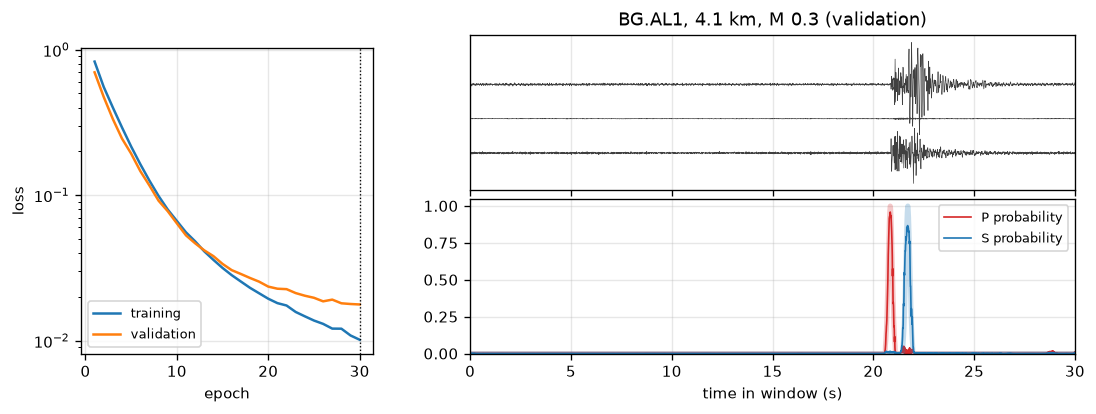

In [25]:
def predict(net, idx):
    with torch.no_grad():
        return np.concatenate([F.softmax(net(X_t[b].to(DEVICE)), 1).cpu().numpy()
                               for b in torch.tensor(idx).split(128)])


prob_va = predict(picker, idx_va)
fig = plt.figure(figsize=(9, 3.4))
ax0 = fig.add_axes([0.06, 0.15, 0.27, 0.75])
ax0.semilogy(np.arange(1, len(hist) + 1), hist[:, 0], label="training")
ax0.semilogy(np.arange(1, len(hist) + 1), hist[:, 1], label="validation")
ax0.axvline(best_ep + 1, c="k", ls=":", lw=0.8)
ax0.set(xlabel="epoch", ylabel="loss"); ax0.legend(fontsize=8)
j = int(np.where(idx_va == meta.index[(meta.set == "val") & meta.s_labelled
                                      & meta.distance_km.between(4, 8)][0])[0][0])
i = idx_va[j]
ax1 = fig.add_axes([0.42, 0.55, 0.56, 0.38]); ax2 = fig.add_axes([0.42, 0.15, 0.56, 0.38], sharex=ax1)
for k in range(3):
    ax1.plot(t, X_all[i, k] / 8 + 2 - k, lw=0.4, c="0.25")
ax1.set(yticks=[], title=f"{meta.network[i]}.{meta.station[i]}, {meta.distance_km[i]:.1f} km, "
                         f"M {meta.magnitude[i]:.1f} (validation)")
for k, (name, col) in enumerate((("P", "tab:red"), ("S", "tab:blue")), start=1):
    ax2.plot(t, Y_all[i, k], c=col, lw=3, alpha=0.25)
    ax2.plot(t, prob_va[j, k], c=col, lw=1, label=f"{name} probability")
ax2.set(xlabel="time in window (s)", ylim=(0, 1.05), xlim=(0, 30)); ax2.legend(fontsize=8)
plt.setp(ax1.get_xticklabels(), visible=False)
plt.show()


Training and validation losses fall together, and the predicted probabilities (thin lines) sit on
the labels (wide pale lines). A.10 turns these probabilities into picks and scores them.

## A.9 · Learned or memorised?

The network has about 270,000 parameters and only about 1,300 training windows. With so many
parameters it could memorise every training window — learn the noise of each one by heart — and
still pick nothing new. Why did it not? To see what memorising looks like, we train the same
network on just **40 windows**, in mini-batches of 8, for 300 epochs.


40 training windows: final training loss 0.0032, validation loss 0.0404 (lowest 0.0391)
all 1282 training windows: training loss 0.0101, validation loss 0.0177


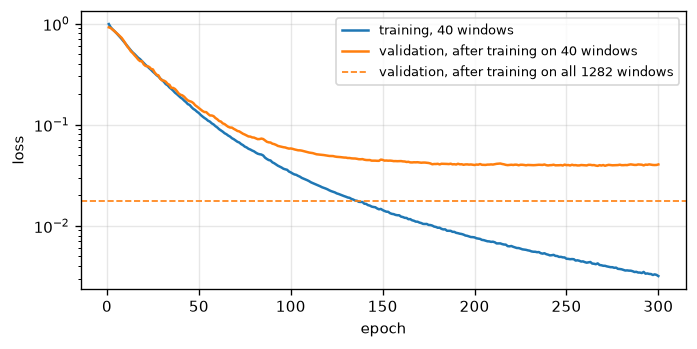

In [26]:
small = np.random.default_rng(1).choice(idx_tr, 40, replace=False)
net_small, hist_small, best_small = fit(small, epochs=300, batch=8, verbose=False)
print(f"40 training windows: final training loss {hist_small[-1, 0]:.4f}, validation loss "
      f"{hist_small[-1, 1]:.4f} (lowest {hist_small[:, 1].min():.4f})")
print(f"all {len(idx_tr)} training windows: training loss {hist[-1, 0]:.4f}, "
      f"validation loss {hist[:, 1].min():.4f}")

fig, ax = plt.subplots(figsize=(6.5, 3.0))
ep = np.arange(1, len(hist_small) + 1)
ax.semilogy(ep, hist_small[:, 0], c="tab:blue", label="training, 40 windows")
ax.semilogy(ep, hist_small[:, 1], c="tab:orange", label="validation, after training on 40 windows")
ax.axhline(hist[:, 1].min(), c="tab:orange", ls="--", lw=1,
           label=f"validation, after training on all {len(idx_tr)} windows")
ax.set(xlabel="epoch", ylabel="loss"); ax.legend(fontsize=8)
plt.show()


With 40 windows the training loss keeps falling, far below anything the full training run reached,
while the validation loss stops improving and stays more than twice as high as with all the
windows (dashed). The gap between the two curves is the network fitting the particular noise of its
40 windows, which tells it nothing about new ones. That is **overfitting**, the bias–variance
trade-off of Session 1 in a network: the training loss measures memory, only the validation loss
measures learning.

**The best remedy for overfitting is more data**, and the second best is data that are varied. A
network trained on a few thousand windows, from earthquakes all over the field, of every size and
at every distance, cannot memorise them all, so it has to learn what is common to them: what an
arrival looks like. The common remedies, besides early stopping, are:

- **data augmentation**: make new training examples by changes that do not change the answer. Our
  windows place the P at a random position, so the network cannot learn a position, and PhaseNet
  also adds noise and stacks two earthquakes in one window;
- **weight decay**: add $\lambda \sum \theta^2$ to the loss, the ridge penalty of Session 1, which
  keeps the weights small (Adam's variant is called AdamW);
- **dropout**: during training, set a random fraction of the neurons' outputs to zero at every
  step, so no neuron can rely on any single other one. `UNet2018` can apply it after every layer.


## A.10 · From probabilities to picks, and how good they are

A pick is a time, not a curve. PhaseNet turns each probability trace into picks with one rule: a
pick is a **local maximum** of the probability that is higher than a **threshold**, and is the
highest value within half a second either side. Its time is the sample of the maximum, and its
probability is the pick's score. PhaseNet's default threshold is 0.3.


In [27]:
def detect_picks(prob, vmin=0.3, kernel=101):
    """PhaseNet's peak picking: samples that are the maximum of their +-kernel//2 neighbourhood and
    exceed vmin. Returns (sample indices, probabilities)."""
    p = torch.as_tensor(np.asarray(prob, np.float32))[None, None]
    smax = F.max_pool1d(p, kernel, stride=1, padding=kernel // 2)
    keep = ((smax == p) & (p > vmin))[0, 0].numpy()
    idx = np.nonzero(keep)[0]
    return idx, np.asarray(prob)[idx]


A pick is **correct** if it lies within 0.1 s (10 samples) of a label, the tolerance used to score
PhaseNet. Counting over windows:

- a **true positive** is a label with a correct pick;
- a **false negative** is a label with no pick near it — a missed arrival;
- a **false positive** is a pick near no label — an arrival that is not there.

Two numbers summarise them. **Precision** is the fraction of picks that are correct,
TP / (TP + FP); **recall** is the fraction of labelled arrivals that were found, TP / (TP + FN).
Raising the threshold makes fewer, surer picks: precision rises and recall falls. The **F1 score**,
$2PR/(P+R)$, is high only when both are.

One subtlety comes from A.5. An S pick on a window with no S label cannot be scored: the S may be
there, unlabelled. So S is scored only on windows that carry an S label, and on noise windows,
where any pick is false.


In [28]:
TOL = 10


def score(prob, idx, k, vmin=0.3):
    """Per-window counts for phase k (1 = P, 2 = S) on windows idx."""
    labels = P_all if k == 1 else S_all
    rows = []
    for j, i in enumerate(idx):
        r = meta.loc[i]
        if k == 2 and r.kind != "noise" and not r.s_labelled:
            continue                                                     # S unknown: not scored
        picks, _ = detect_picks(prob[j, k], vmin)
        truth = labels[i][labels[i] >= 0]
        hit = [t for t in truth if len(picks) and np.abs(picks - t).min() <= TOL]
        res = [int(picks[np.abs(picks - t).argmin()] - t) for t in hit]
        rows.append(dict(i=i, mbin=r.mbin, dbin=r.dbin, instrument=r.instrument, kind=r.kind,
                         remark=r.p_remark, tp=len(hit), fn=len(truth) - len(hit),
                         fp=len(picks) - len(hit), res=res))
    return pd.DataFrame(rows)


def summary(d):
    tp, fp, fn = d.tp.sum(), d.fp.sum(), d.fn.sum()
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return pd.Series(dict(precision=p, recall=r, F1=2 * p * r / max(p + r, 1e-9), n=tp + fn))


# The threshold is a decision, so it is chosen on validation, never on test.
for vmin in (0.1, 0.3, 0.5, 0.7):
    sp, ss = summary(score(prob_va, idx_va, 1, vmin)), summary(score(prob_va, idx_va, 2, vmin))
    print(f"threshold {vmin}: P precision {sp.precision:.2f} recall {sp.recall:.2f} F1 {sp.F1:.2f} | "
          f"S precision {ss.precision:.2f} recall {ss.recall:.2f} F1 {ss.F1:.2f}")


threshold 0.1: P precision 0.75 recall 0.81 F1 0.78 | S precision 0.79 recall 0.82 F1 0.81


threshold 0.3: P precision 0.84 recall 0.80 F1 0.82 | S precision 0.82 recall 0.80 F1 0.81


threshold 0.5: P precision 0.87 recall 0.79 F1 0.83 | S precision 0.84 recall 0.79 F1 0.81


threshold 0.7: P precision 0.92 recall 0.76 F1 0.83 | S precision 0.86 recall 0.72 F1 0.78


The F1 score changes little between 0.3 and 0.5, so we keep PhaseNet's 0.3. Now, once, the **test
set**: earthquakes from cells the network never saw, balanced over magnitude and distance.


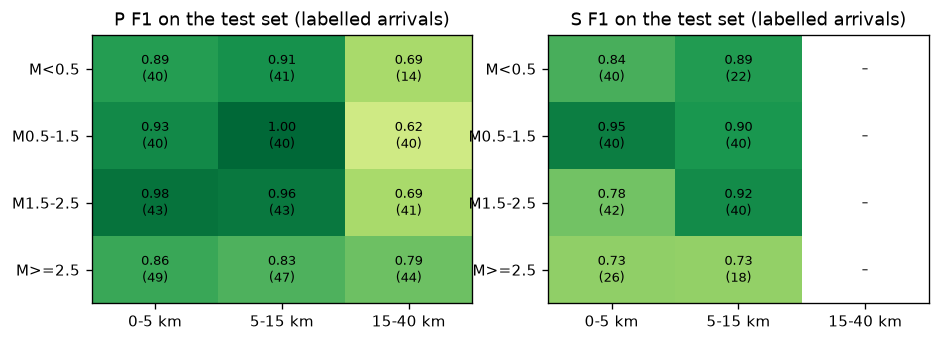

P, all test windows: precision 0.87, recall 0.82, F1 0.85 over 482 labelled arrivals; false picks on the 68 noise windows: 14
S, all test windows: precision 0.85, recall 0.84, F1 0.84 over 268 labelled arrivals; false picks on the 68 noise windows: 8


In [29]:
prob_te = predict(picker, idx_te)
sc_P, sc_S = score(prob_te, idx_te, 1), score(prob_te, idx_te, 2)
order_m, order_d = ["M<0.5", "M0.5-1.5", "M1.5-2.5", "M>=2.5"], ["0-5 km", "5-15 km", "15-40 km"]
fig, axs = plt.subplots(1, 2, figsize=(9, 2.9))
for ax, d, name in ((axs[0], sc_P, "P"), (axs[1], sc_S, "S")):
    f1 = (d[d.kind == "event"].groupby(["mbin", "dbin"]).apply(lambda g: summary(g).F1)
          .unstack().reindex(index=order_m, columns=order_d))
    n = (d[d.kind == "event"].groupby(["mbin", "dbin"]).apply(lambda g: summary(g).n)
         .unstack().reindex(index=order_m, columns=order_d))
    ax.imshow(f1.values, vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
    for a in range(len(order_m)):
        for b in range(len(order_d)):
            v, m = f1.values[a, b], n.values[a, b]
            ax.text(b, a, "–" if not m == m or m < 5 else f"{v:.2f}\n({int(m)})", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(3), order_d); ax.set_yticks(range(4), order_m)
    ax.set_title(f"{name} F1 on the test set (labelled arrivals)"); ax.grid(False)
plt.show()
for name, d in (("P", sc_P), ("S", sc_S)):
    s = summary(d)
    print(f"{name}, all test windows: precision {s.precision:.2f}, recall {s.recall:.2f}, F1 {s.F1:.2f} "
          f"over {int(s.n)} labelled arrivals; false picks on the {int((d.kind == 'noise').sum())} noise "
          f"windows: {int(d[d.kind == 'noise'].fp.sum())}")


The picker is best for larger earthquakes recorded nearby, and degrades towards small earthquakes
and large distances, where the arrival is weak against the noise. For S, the far column is empty:
almost no S is labelled beyond 15 km, so there is nothing to score — not evidence that the picker
fails there. Because the test set is balanced, each cell is measured with comparable precision,
and the overall numbers weight all cells similarly. A test set drawn in natural proportions, mostly
small and near, would report a single number that hides the far column.

### How precise are the correct picks?

The analyst's pick is not the truth either. Each P label carries the analyst's quality remark:
**impulsive** (i), a sharp onset, or **emergent** (e), a gradual one whose start is uncertain.


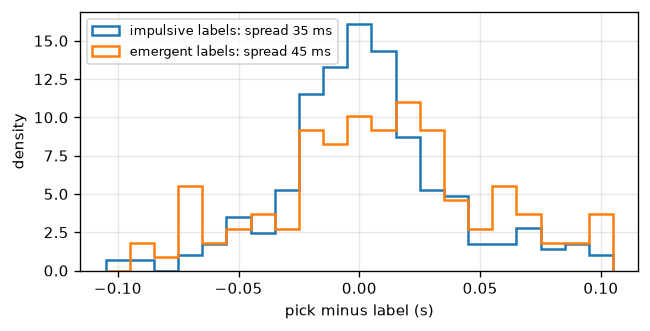

P residuals (correct picks): median 0 ms, standard deviation 38 ms


In [30]:
res = sc_P[sc_P.kind == "event"].explode("res").dropna(subset=["res"])
res["res_s"] = res.res.astype(float) / FS
fig, ax = plt.subplots(figsize=(6, 2.8))
bins = np.arange(-0.105, 0.11, 0.01)
for rem, col in (("i", "tab:blue"), ("e", "tab:orange")):
    x = res[res.remark.astype(str).str.lower().str.startswith(rem)].res_s
    ax.hist(x, bins, histtype="step", lw=1.5, color=col, density=True,
            label=f"{'impulsive' if rem == 'i' else 'emergent'} labels: spread {x.std() * 1000:.0f} ms")
ax.set(xlabel="pick minus label (s)", ylabel="density"); ax.legend(fontsize=8)
plt.show()
print(f"P residuals (correct picks): median {res.res_s.median() * 1000:.0f} ms, "
      f"standard deviation {res.res_s.std() * 1000:.0f} ms")


Picks agree with impulsive labels more closely than with emergent ones. Part of that spread is the
label's own uncertainty: when the analyst could not see the onset clearly, no picker can be
scored better than the analyst's guess. A network cannot be more precise than its labels.

### Against STA/LTA

The baseline every seismic network ran for decades is the STA/LTA trigger of A.6. As a P picker we
take the first time the ratio exceeds a threshold, chosen on the validation set for the best F1, and
score it exactly like the network.


In [31]:
def sta_lta_picks(idx, on):
    out = np.zeros((len(idx), 3, NT), np.float32)
    for j, i in enumerate(idx):
        z = X_all[i, 2] if X_all[i, 2].any() else X_all[i].max(0)
        r = sta_lta(z)
        above = np.nonzero(r > on)[0]
        if len(above):
            out[j, 1, above[0]] = 1.0                       # one pick: the first trigger
    return out


best_on = max((summary(score(sta_lta_picks(idx_va, on), idx_va, 1, 0.5)).F1, on) for on in (3, 4, 6, 8, 12))[1]
sc_sl = score(sta_lta_picks(idx_te, best_on), idx_te, 1, 0.5)
for name, d in (("STA/LTA", sc_sl), ("UNet2018", sc_P)):
    by_d = d[d.kind == "event"].groupby("dbin").apply(lambda g: summary(g).F1).reindex(order_d)
    print(f"{name:<9} P F1 by distance: " + ", ".join(f"{k} {v:.2f}" for k, v in by_d.items())
          + f";  overall {summary(d).F1:.2f}")
print(f"(STA/LTA trigger level chosen on validation: {best_on})")


STA/LTA   P F1 by distance: 0-5 km 0.69, 5-15 km 0.67, 15-40 km 0.28;  overall 0.56
UNet2018  P F1 by distance: 0-5 km 0.91, 5-15 km 0.92, 15-40 km 0.71;  overall 0.85
(STA/LTA trigger level chosen on validation: 4)


STA/LTA finds the strong, near arrivals, but it times them by when the energy ratio crosses a
level, which is after the onset, and it fires on noise bursts. The network, trained on analysts'
picks, times arrivals the way the analysts did and keeps its precision at distance.

## A.11 · The labels decide what is learnable

A.5 showed that most S arrivals are not labelled, and that the gaps are not random: they grow with
distance and with vertical-only sensors. In A.8 we trained with the simplest rule — every sample
without a label is noise — so on a window with no S label, the network was taught that the S
arrival in it is noise. What did that teach?

The fix is to teach only what we know. On a window without an S label, over the stretch where the
S could arrive — from just after the P until $0.15\,\mathrm{s/km} \times$ distance $+ 1$ s later,
which covers the S–P time at any distance in the field — we do not know whether a sample is noise
or S. We do know it is **not P**: the P was picked, and it came earlier. So there we replace the
loss by the likelihood of what we know, a **partial label**:

$$L_i = -\ln\left(p_\text{noise} + p_S\right),$$

which is zero whenever the network puts all its probability on noise or S, and does not care how
it divides it between them. Everywhere else, including the coda after that stretch, the full label
stands. (Simply leaving the stretch out of the loss — **masking** it, as PhaseNet-Plus's
`phase_mask` can — also stops the network learning that S is noise, but then nothing tells it that
an arrival in that stretch is not a P, and it starts calling distant S arrivals P.) We retrain with
the partial label, everything else the same.


In [32]:
def s_unknown():
    """1 where a window has no S label and the S could be: the network is told only 'not P'."""
    U = np.zeros((len(meta), NT), np.float32)
    for i in meta.index[(meta.kind == "event") & ~meta.s_labelled]:
        p = P_all[i][P_all[i] >= 0]
        if len(p):
            a = p.min() + 20
            U[i, a:a + int((0.15 * meta.distance_km[i] + 1.0) * FS)] = 1
    return U


picker_partial, hist_m, best_m = fit(idx_tr, not_p=s_unknown(), verbose=False)
prob_te_m = predict(picker_partial, idx_te)
for name, pr in (("every gap is noise", prob_te), ("partial label", prob_te_m)):
    print(f"{name:<19}: P F1 {summary(score(pr, idx_te, 1)).F1:.2f}, S F1 on labelled S "
          f"{summary(score(pr, idx_te, 2)).F1:.2f}")


every gap is noise : P F1 0.85, S F1 on labelled S 0.84


partial label      : P F1 0.85, S F1 on labelled S 0.88


On the arrivals we can score, the two networks are close for P, and the partial label scores
somewhat better on S. The real difference is where we cannot score: the S arrivals nobody labelled.
There is still a physical test. For a wave path of length $R$, the S–P time is
$R\,(1/v_S - 1/v_P)$: it grows with distance, and it can be no shorter than for the fastest rock
the waves could have crossed. In crust no faster than $v_P = 6$ km/s, with the usual ratio
$v_P/v_S = 1.73$, that floor is about 0.12 s per kilometre of epicentral distance (the path is
never shorter than the epicentral distance). A pick far below the floor cannot be an S. We take
every test window **without** an S label and plot each network's S picks against the floor, beside
the analysts' S picks on labelled windows.


S-P floor: 0.122 s/km, so at least 3.6 s at 30 km; analysts' S picks below 0.7 x floor: 0%
every gap is noise: S picks on 54 of 191 unlabelled test windows; within 15 km 41 (0% too early to be S), beyond 15 km 13 (31% too early)
partial label: S picks on 103 of 191 unlabelled test windows; within 15 km 48 (0% too early to be S), beyond 15 km 55 (64% too early)


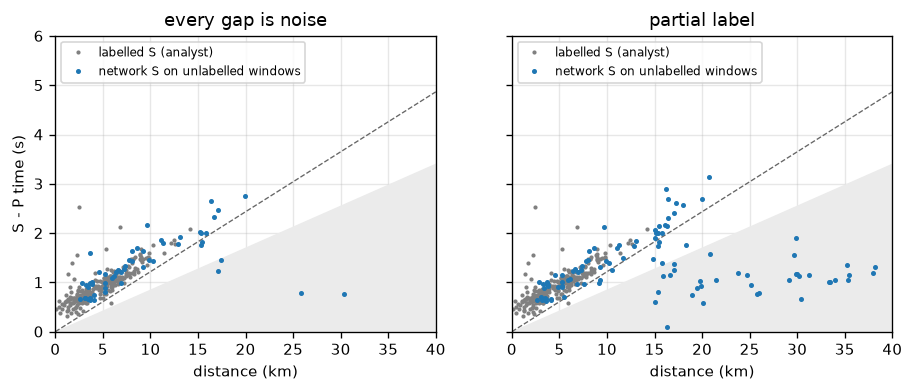

In [33]:
def s_minus_p(prob, idx, labelled):
    """Distance and S-P time (s): the analyst's S on labelled windows, the network's on unlabelled."""
    d, sp = [], []
    for j, i in enumerate(idx):
        r = meta.loc[i]
        if r.kind != "event" or r.s_labelled != labelled:
            continue
        p0 = P_all[i][P_all[i] >= 0].min()
        s = S_all[i][S_all[i] >= 0] if labelled else detect_picks(prob[j, 2])[0]
        s = s[s > p0]
        if len(s):
            d.append(r.distance_km); sp.append((s.min() - p0) / FS)
    return np.array(d), np.array(sp)


n_unlab = int(((meta.set == "test") & (meta.kind == "event") & ~meta.s_labelled).sum())
dl, spl = s_minus_p(prob_te, idx_te, True)
vp, vpvs = 6.0, 1.73
floor = (vpvs - 1) / vp                                          # s of S-P per km, fastest crust
print(f"S-P floor: {floor:.3f} s/km, so at least {30 * floor:.1f} s at 30 km; analysts' S picks below "
      f"0.7 x floor: {np.mean(spl < 0.7 * floor * dl):.0%}")
dd = np.linspace(0, 40, 2)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, pr, name in ((axs[0], prob_te, "every gap is noise"), (axs[1], prob_te_m, "partial label")):
    du, spu = s_minus_p(pr, idx_te, False)
    too_early = spu < 0.7 * floor * du                           # well below the floor: not an S
    ax.fill_between(dd, 0, 0.7 * floor * dd, color="0.92")
    ax.plot(dd, floor * dd, c="0.4", lw=0.8, ls="--")
    ax.plot(dl, spl, ".", c="0.5", ms=3, label="labelled S (analyst)")
    ax.plot(du, spu, ".", c="tab:blue", ms=4, label="network S on unlabelled windows")
    ax.set(xlabel="distance (km)", title=name, xlim=(0, 40), ylim=(0, 6))
    ax.legend(fontsize=7, loc="upper left")
    far = du > 15
    print(f"{name}: S picks on {len(du)} of {n_unlab} unlabelled test windows; within 15 km "
          f"{np.sum(~far)} ({np.mean(too_early[~far]):.0%} too early to be S), beyond 15 km {np.sum(far)} "
          f"({np.mean(too_early[far]) if far.any() else 0:.0%} too early)")
axs[0].set_ylabel("S - P time (s)")
plt.show()


The dashed line is the floor and the shaded wedge lies well below it; the analysts' S picks sit
above it, as they must. Within 15 km both networks pick S on unlabelled windows, the partial-label
network more of them, and almost none fall in the wedge: they behave like real S arrivals the
analysts did not pick. The
network trained with every gap as noise picks far fewer: it learned that much of what follows a P
is noise — exactly what its labels said. **A network learns its labels, including their
omissions.**

Beyond 15 km the physics gives a sharper verdict. The partial-label network now makes many "S"
picks there, but many sit about a second after the P, inside the wedge: at 30 km a real S comes at
least several seconds after the P. These picks are not S. They are most likely a later P arrival — at
these distances the first arrival is a head wave, and the direct P that A.1 described follows it.
The partial label stopped the network learning that distant S is noise, but it could not teach it
what a distant S looks like, because no training window had a labelled S beyond about 15 km. **A
loss can stop a network learning the wrong thing from missing labels; only labels can teach it the
right thing.** No score on labelled arrivals could have shown this; the S–P line did.

## A.12 · Does a probability of 0.5 mean a 50 % chance?

Each pick carries a probability. Is it a probability in the everyday sense — of all the picks
scored 0.5, are half correct? A predictor whose probabilities mean this is **calibrated**. Session
2 asked the same of an error ellipse: does the 95 % ellipse contain the truth 95 % of the time?

The check is a **reliability diagram**. Take every P pick on the test set, at a low threshold of
0.05 so that weak picks are included, group the picks by their probability, and plot the fraction
correct in each group against the group's mean probability. A calibrated picker lies on the
diagonal. Each group is a sample of picks, so its fraction correct has an uncertainty: we draw the
binomial standard error, $\sqrt{f(1-f)/n}$ for a fraction $f$ of $n$ picks. The **expected
calibration error** (ECE) is the average distance from the diagonal, each group weighted by its
number of picks.


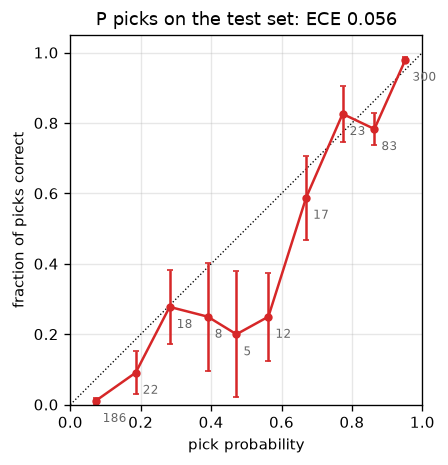

674 P picks; 46% have probability above 0.9, and 98% of those are correct; picks between 0.3 and 0.7: 45, 33% correct


In [34]:
def pick_scores(prob, idx, k=1):
    """Every pick at threshold 0.05, its probability, and whether it is within TOL of a label."""
    labels = P_all if k == 1 else S_all
    ps, ok = [], []
    for j, i in enumerate(idx):
        picks, pv = detect_picks(prob[j, k], 0.05)
        truth = labels[i][labels[i] >= 0]
        for t_, v in zip(picks, pv):
            ps.append(v); ok.append(len(truth) > 0 and np.abs(truth - t_).min() <= TOL)
    return np.array(ps), np.array(ok, float)


ps, ok = pick_scores(prob_te, idx_te)
edges = np.linspace(0.05, 1, 11)
b = np.clip(np.digitize(ps, edges) - 1, 0, 9)
n = np.bincount(b, minlength=10)
conf = np.array([ps[b == k].mean() for k in range(10)])
frac = np.array([ok[b == k].mean() for k in range(10)])
err = np.sqrt(frac * (1 - frac) / n)
ece = np.sum(n * np.abs(frac - conf)) / n.sum()

fig, ax = plt.subplots(figsize=(4.4, 4))
ax.plot([0, 1], [0, 1], c="k", lw=0.8, ls=":")
ax.errorbar(conf, frac, err, fmt="o-", c="tab:red", ms=4, capsize=2)
for c_, f_, n_ in zip(conf, frac, n):
    ax.text(c_ + 0.02, f_ - 0.06, str(n_), fontsize=7, color="0.4")
ax.set(xlabel="pick probability", ylabel="fraction of picks correct", xlim=(0, 1), ylim=(0, 1.05),
       aspect="equal", title=f"P picks on the test set: ECE {ece:.3f}")
plt.show()
print(f"{len(ps)} P picks; {np.mean(ps > 0.9):.0%} have probability above 0.9, and {ok[ps > 0.9].mean():.0%} "
      f"of those are correct; picks between 0.3 and 0.7: {np.sum((ps > 0.3) & (ps < 0.7))}, "
      f"{ok[(ps > 0.3) & (ps < 0.7)].mean():.0%} correct")


The grey numbers are the picks in each group. Almost half the picks are confident, above 0.9, and
nearly all of those are correct: at the top the curve meets the diagonal. Below about 0.6 it lies
under the diagonal, beyond its error bars: a pick scored 0.5 is right only about a quarter of the
time. The weak picks are **overconfident**. The ECE is nevertheless small, because it weights each
group by its number of picks and few picks are weak — a single number that hides where the
calibration fails. So the answer to the question is no: here a 0.5 means roughly a one-in-four
chance, and only the strong picks mean what they say.

Even where it holds, calibration is a measurement, not a guarantee. A network's softmax outputs are not probabilities by
construction, because training rewards being right, not being honest about doubt, and large modern
networks are often overconfident (Guo et al. 2017). Calibration also changes when the data change:
a picker trained on one region and run on another may keep its ranking of picks while its
probabilities drift. So **a threshold such as 0.5 is a number on a scale the network invented**,
and before a probability is used as one — to weight a pick in a location, to decide what an analyst
should review — its reliability diagram must be measured on data the network did not train on.
Part B asks this of the published PhaseNet on Geysers data.

### Optional: recalibrating

When a reliability curve does lie off the diagonal, it can be corrected after training without
changing which picks are found. **Temperature scaling** divides every logit by one number $T$ before
the softmax, fitted on the validation set: $T > 1$ softens the probabilities and $T < 1$ sharpens
them (Guo et al. 2017). Fitting a monotone function of the pick score to whether picks were correct
on the validation set — a logistic curve (Platt scaling) or a step function (isotonic regression) —
does the same at the level of picks. Because each is monotone, a stronger pick stays stronger: the
ranking, and so the precision–recall trade-off, is unchanged, and only what a number means moves.

## A.13 · The programs the field runs

- **STA/LTA** (Allen 1978) and its descendants, the trigger in almost every network's real-time
  system for four decades. Hand-designed convolutions (A.6).
- **PhaseNet** (Zhu & Beroza 2018), the U-Net of A.8, trained on northern California picks. Our
  `UNet2018` has its layers, but not the original's padding; the published weights need that
  padding to reproduce PhaseNet's picks, so Part B adds it before running them.
- **GPD** (Ross et al. 2018), a convolutional network that classifies short windows as P, S or
  noise — the detector of A.6 grown up — slid along the trace.
- **EQTransformer** (Mousavi et al. 2020), which adds attention layers and detects the earthquake
  and picks its phases together.
- **SeisBench** (Woollam et al. 2022), the common library that packages these networks, their
  published weights and benchmark datasets in one interface, so that pickers can be compared on the
  same data. It is the obvious tool for a student who wants to use a picker today.
- **PhaseNet-Plus**, our group's current code, which adds first-motion polarity and event
  detection heads and the label mask of A.11; the functions in this notebook are distilled from it.

## Takeaways

**Machine learning**

- A neural network is a flexible function of many parameters — with ReLU activations, a
  piecewise-linear one — fitted by minimising a loss, as least squares is.
- Backpropagation is the chain rule applied from the loss backwards, and it gives the gradient with
  respect to every parameter for about the cost of one forward pass.
- Gradient descent needs a learning rate found by watching the loss; mini-batches, momentum and
  Adam make it fast, and more neurons than strictly needed make it reliable.
- Softmax and cross-entropy turn a network's outputs into class probabilities and score them by
  likelihood; soft Gaussian labels make the loss PhaseNet's KL divergence.
- Convolution shares one small kernel across all positions, so a convolutional network recognises
  an arrival wherever it occurs and generalises where a fully connected network does not.
- A U-Net shortens the trace to see context and restores timing through skip connections, so it
  can give a probability at every sample.
- Overfitting shows as a validation loss that rises while the training loss falls; more varied
  data, augmentation and early stopping prevent it.
- A network learns its labels including their omissions: a loss that scores only what is known
  (here, "not P") stops it learning that unlabelled arrivals are noise, but only labels can teach it
  what those arrivals look like.
- A softmax output is not a calibrated probability by construction; whether it is must be measured
  with a reliability diagram on held-out data.

**Seismology**

- A phase picker turns a three-component seismogram into P and S arrival times, the input to
  association, location and everything after them in this course.
- Records of one earthquake share its source, and nearby earthquakes share paths, so a picker is
  tested on earthquakes from places it never trained on, split by space, not at random.
- Picking skill depends on magnitude and distance, so a picker is scored on a test set balanced
  over both, and reported per combination.
- Catalogue S picks are missing mostly at distance and on vertical-only sensors, so an unlabelled
  S is not an absent S.
- A picker's timing can be no better than its labels: picks agree more closely with impulsive than
  with emergent analyst picks.
- S–P time grows in proportion to distance, which gives a physical check on picks that no label can
  score, and it shows that distant "S" picks learned without distant S labels are not S.

## References

- Allen, R. V. (1978). Automatic earthquake recognition and timing from single traces. *Bull.
  Seismol. Soc. Am.*, 68, 1521–1532. https://doi.org/10.1785/BSSA0680051521
- Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural
  networks. *ICML*. https://arxiv.org/abs/1706.04599
- He, K., Zhang, X., Ren, S., & Sun, J. (2015). Delving deep into rectifiers. *ICCV*.
  https://arxiv.org/abs/1502.01852
- Ioffe, S., & Szegedy, C. (2015). Batch normalization. *ICML*. https://arxiv.org/abs/1502.03167
- Karpathy, A. (2019). A recipe for training neural networks.
  http://karpathy.github.io/2019/04/25/recipe/
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*.
  https://arxiv.org/abs/1412.6980
- Mousavi, S. M., Ellsworth, W. L., Zhu, W., Chuang, L. Y., & Beroza, G. C. (2020). Earthquake
  transformer. *Nat. Commun.*, 11. https://doi.org/10.1038/s41467-020-17591-w
- Prince, S. J. D. (2023). *Understanding Deep Learning*. MIT Press. https://udlbook.github.io/udlbook/
- Ronneberger, O., Fischer, P., & Brox, T. (2015). U-Net: Convolutional networks for biomedical
  image segmentation. *MICCAI*, 234–241. https://doi.org/10.1007/978-3-319-24574-4_28
- Ross, Z. E., Meier, M.-A., Hauksson, E., & Heaton, T. H. (2018). Generalized seismic phase
  detection with deep learning. *Bull. Seismol. Soc. Am.*, 108, 2894–2901.
  https://doi.org/10.1785/0120180080
- Woollam, J., Münchmeyer, J., Tilmann, F., Rietbrock, A., et al. (2022). SeisBench — a toolbox for
  machine learning in seismology. *Seismol. Res. Lett.*, 93, 1695–1709.
  https://doi.org/10.1785/0220210324
- Zhu, W., & Beroza, G. C. (2018). PhaseNet: a deep-neural-network-based seismic arrival-time
  picking method. *Geophys. J. Int.* https://doi.org/10.1093/gji/ggy423